Analytical saddle-node
----------------------
lambda_SN = 31.1257272950
I_SN      = 152.55004304
x_SN      = 0.01711808

Reconstructed fold equilibrium
------------------------------
S                  = 172255.73336780115
V                  = 805387.9998276612
E                  = 122.04003443497531
I                  = 152.55004304371914
R_N                = 21891.047169734873
R_V                = 190.62955732405908
T                  = 0.0949646207723503
x                  = 0.01711807972555816
population_error   = 0.0


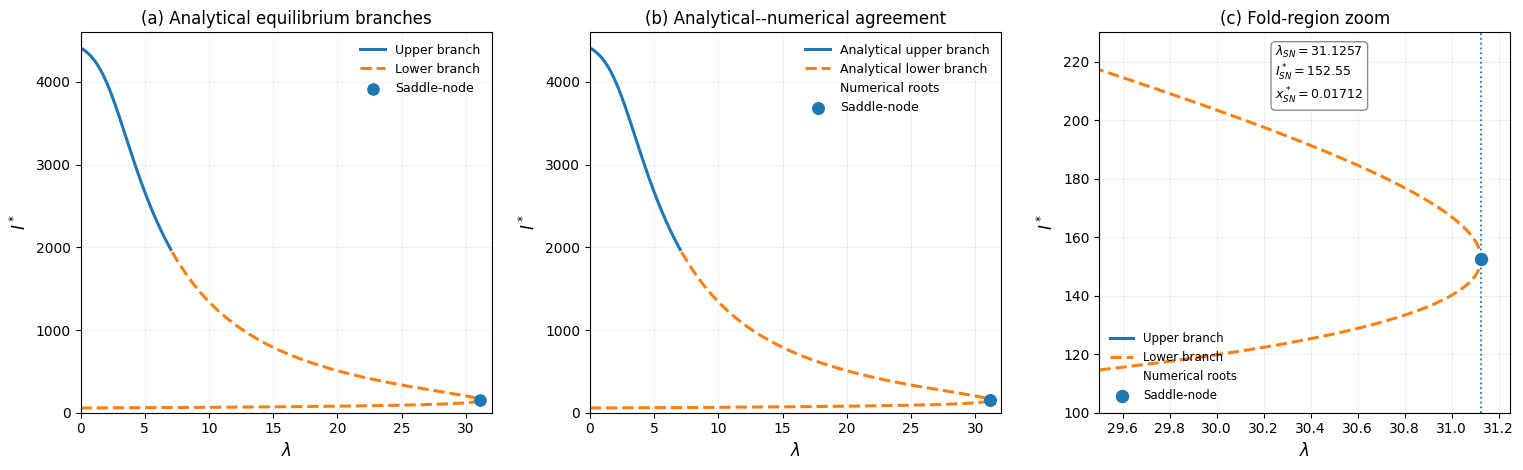

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root

# ============================================================
# Nonlinear trust-vaccination epidemic model:
# analytical branches + numerical root verification + fold point
# ============================================================

# -----------------------------
# Baseline parameters
# -----------------------------
N = 1_000_000
beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2
omega_V = 1 / 365
omega_N = 1 / (365 * 2)
mu = 0.05
k = 10
T_c = 0.5

# -----------------------------
# Analytical reduction constants
# -----------------------------
a = 1 + gamma / sigma + gamma / omega_N
b = gamma * (1 / omega_V - 1 / omega_N)
q = gamma / ((1 - epsilon) * beta) - 1
c = k * T_c


def coeffs(x):
    """
    Coefficients of the reduced quadratic equilibrium equation
        Q(i,x) = A(x)i^2 + B(x)i + C(x) = 0.
    """
    A = beta * (a + b * x)
    B = phi * x * (a + b * x) + gamma - beta
    C = phi * x * q
    return A, B, C


def Q(i, x):
    A, B, C = coeffs(x)
    return A * i**2 + B * i + C


def candidate_i_roots(x):
    """
    Positive endemic-fraction candidates for a fixed vaccination
    preference x.
    """
    A, B, C = coeffs(x)
    D = B**2 - 4 * A * C

    if D <= 0:
        return []

    sqrt_D = np.sqrt(D)

    r1 = (-B - sqrt_D) / (2 * A)
    r2 = (-B + sqrt_D) / (2 * A)

    return sorted([r1, r2])


def theta_from_x_i(x, i):
    return (c + np.log(x / (1 - x))) / i


def lambda_from_x_i(x, i):
    return (mu / k) * theta_from_x_i(x, i)


# ============================================================
# Analytical equilibrium branches
# ============================================================

# Positive lambda requires
# c + log(x/(1-x)) > 0.
x_floor = 1 / (1 + np.exp(c)) + 1e-8

# Dense grid gives smooth analytical curves.
x_grid = np.linspace(x_floor, 0.12, 40000)

branch_low = []
branch_high = []

for x in x_grid:
    roots = candidate_i_roots(x)

    if len(roots) != 2:
        continue

    i_low, i_high = roots

    for container, i in [
        (branch_low, i_low),
        (branch_high, i_high),
    ]:
        if i <= 0:
            continue

        lam = lambda_from_x_i(x, i)

        if np.isfinite(lam) and 0 < lam <= 32:
            container.append((lam, N * i, x))

branch_low = np.asarray(branch_low)
branch_high = np.asarray(branch_high)


# ============================================================
# Independent numerical verification of the equivalent reduced
# equilibrium equation at fixed lambda
# ============================================================

def x_of_i_lambda(i, lam):
    return 1 / (1 + np.exp(-k * (lam * i / mu - T_c)))


def G(i, lam):
    """
    Equivalent reduced equilibrium equation after substituting
    the behavioral relation x(i,lambda).
    """
    return Q(i, x_of_i_lambda(i, lam))


def numerical_roots(lam):
    """
    Find all positive roots of G(i,lambda)=0 at fixed lambda
    using sign-change bracketing and Brent's method.
    """
    grid = np.unique(
        np.r_[
            np.geomspace(1e-10, 1e-2, 9000),
            np.linspace(1e-2, 0.02, 2000),
        ]
    )

    vals = np.array([G(i, lam) for i in grid])
    roots = []

    for j in range(len(grid) - 1):
        if not np.isfinite(vals[j]) or not np.isfinite(vals[j + 1]):
            continue

        if vals[j] == 0:
            r = grid[j]

        elif vals[j] * vals[j + 1] < 0:
            r = brentq(
                lambda z: G(z, lam),
                grid[j],
                grid[j + 1],
            )

        else:
            continue

        if not roots or abs(r - roots[-1]) > 1e-9:
            roots.append(r)

    return sorted(roots)


# Use fewer lambda values so the numerical markers remain visible.
lambda_grid = np.linspace(0.2, 31.10, 34)

num_low = []
num_high = []

for lam in lambda_grid:
    roots = numerical_roots(lam)

    if len(roots) >= 1:
        num_low.append((lam, N * roots[0]))

    if len(roots) >= 2:
        num_high.append((lam, N * roots[-1]))

num_low = np.asarray(num_low)
num_high = np.asarray(num_high)


# ============================================================
# Analytical saddle-node fold condition
# ============================================================

def derivatives(i, x):
    A, B, _ = coeffs(x)

    Q_i = 2 * A * i + B

    Q_x = (
        beta * b * i**2
        + phi * (a + 2 * b * x) * i
        + phi * q
    )

    return Q_i, Q_x


def fold_system(z):
    i, x = z

    L = c + np.log(x / (1 - x))
    L_prime = 1 / (x * (1 - x))

    Q_i, Q_x = derivatives(i, x)

    return [
        Q(i, x),
        L_prime * i * Q_i + L * Q_x,
    ]


fold_solution = root(
    fold_system,
    [1.5255e-4, 0.017118],
)

if not fold_solution.success:
    raise RuntimeError("Fold solver failed.")

i_SN, x_SN = fold_solution.x
lambda_SN = lambda_from_x_i(x_SN, i_SN)
I_SN = N * i_SN


# ============================================================
# Reconstruct the full endemic equilibrium at the fold
# ============================================================

def reconstruct_full_equilibrium(i, x, lam):
    I = N * i
    T = (lam / mu) * i

    S = N * (
        gamma * i
        / (beta * i + phi * x)
    )

    V = N * (
        phi * x * gamma
        / (
            (1 - epsilon)
            * beta
            * (beta * i + phi * x)
        )
    )

    E = N * (gamma / sigma) * i

    R_N = N * (
        (1 - x) * gamma / omega_N
    ) * i

    R_V = N * (
        x * gamma / omega_V
    ) * i

    population_error = (
        S + V + E + I + R_N + R_V - N
    )

    return {
        "S": S,
        "V": V,
        "E": E,
        "I": I,
        "R_N": R_N,
        "R_V": R_V,
        "T": T,
        "x": x,
        "population_error": population_error,
    }


state = reconstruct_full_equilibrium(
    i_SN,
    x_SN,
    lambda_SN,
)

print("Analytical saddle-node")
print("----------------------")
print(f"lambda_SN = {lambda_SN:.10f}")
print(f"I_SN      = {I_SN:.8f}")
print(f"x_SN      = {x_SN:.8f}")
print()
print("Reconstructed fold equilibrium")
print("------------------------------")
for key, value in state.items():
    print(f"{key:18s} = {value}")


# ============================================================
# Publication-quality figure
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15.5, 4.8),
)

# -----------------------------
# Panel (a): analytical branches
# -----------------------------
axes[0].plot(
    branch_high[:, 0],
    branch_high[:, 1],
    linewidth=2.2,
    label="Upper branch",
)

axes[0].plot(
    branch_low[:, 0],
    branch_low[:, 1],
    linewidth=2.2,
    linestyle="--",
    label="Lower branch",
)

axes[0].scatter(
    [lambda_SN],
    [I_SN],
    s=65,
    zorder=6,
    label="Saddle-node",
)

axes[0].set_xlabel(r"$\lambda$", fontsize=12)
axes[0].set_ylabel(r"$I^*$", fontsize=12)
axes[0].set_title(
    "(a) Analytical equilibrium branches",
    fontsize=12,
)
axes[0].set_xlim(0, 32)
axes[0].set_ylim(0, 4600)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(alpha=0.18)


# -----------------------------
# Panel (b): analytical vs numerical
# -----------------------------
axes[1].plot(
    branch_high[:, 0],
    branch_high[:, 1],
    linewidth=2.2,
    label="Analytical upper branch",
)

axes[1].plot(
    branch_low[:, 0],
    branch_low[:, 1],
    linewidth=2.2,
    linestyle="--",
    label="Analytical lower branch",
)

if len(num_high):
    axes[1].scatter(
        num_high[:, 0],
        num_high[:, 1],
        s=34,
        marker="o",
        facecolors="none",
        linewidths=1.2,
        zorder=5,
        label="Numerical roots",
    )

if len(num_low):
    axes[1].scatter(
        num_low[:, 0],
        num_low[:, 1],
        s=34,
        marker="o",
        facecolors="none",
        linewidths=1.2,
        zorder=5,
    )

axes[1].scatter(
    [lambda_SN],
    [I_SN],
    s=70,
    zorder=7,
    label="Saddle-node",
)

axes[1].set_xlabel(r"$\lambda$", fontsize=12)
axes[1].set_ylabel(r"$I^*$", fontsize=12)
axes[1].set_title(
    "(b) Analytical--numerical agreement",
    fontsize=12,
)
axes[1].set_xlim(0, 32)
axes[1].set_ylim(0, 4600)
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(alpha=0.18)


# -----------------------------
# Panel (c): fold-region zoom
# -----------------------------
mask_high = (
    (branch_high[:, 0] >= 29.5)
    & (branch_high[:, 0] <= 31.25)
    & (branch_high[:, 1] >= 100)
    & (branch_high[:, 1] <= 230)
)

mask_low = (
    (branch_low[:, 0] >= 29.5)
    & (branch_low[:, 0] <= 31.25)
    & (branch_low[:, 1] >= 100)
    & (branch_low[:, 1] <= 230)
)

axes[2].plot(
    branch_high[mask_high, 0],
    branch_high[mask_high, 1],
    linewidth=2.2,
    label="Upper branch",
)

axes[2].plot(
    branch_low[mask_low, 0],
    branch_low[mask_low, 1],
    linewidth=2.2,
    linestyle="--",
    label="Lower branch",
)

if len(num_high):
    mask_num_high = (
        (num_high[:, 0] >= 29.5)
        & (num_high[:, 0] <= 31.25)
        & (num_high[:, 1] >= 100)
        & (num_high[:, 1] <= 230)
    )

    axes[2].scatter(
        num_high[mask_num_high, 0],
        num_high[mask_num_high, 1],
        s=42,
        marker="o",
        facecolors="none",
        linewidths=1.3,
        zorder=5,
        label="Numerical roots",
    )

if len(num_low):
    mask_num_low = (
        (num_low[:, 0] >= 29.5)
        & (num_low[:, 0] <= 31.25)
        & (num_low[:, 1] >= 100)
        & (num_low[:, 1] <= 230)
    )

    axes[2].scatter(
        num_low[mask_num_low, 0],
        num_low[mask_num_low, 1],
        s=42,
        marker="o",
        facecolors="none",
        linewidths=1.3,
        zorder=5,
    )

axes[2].scatter(
    [lambda_SN],
    [I_SN],
    s=75,
    zorder=7,
    label="Saddle-node",
)

axes[2].axvline(
    lambda_SN,
    linestyle=":",
    linewidth=1.3,
)

axes[2].annotate(
    (
        rf"$\lambda_{{SN}}={lambda_SN:.4f}$"
        "\n"
        rf"$I^*_{{SN}}={I_SN:.2f}$"
        "\n"
        rf"$x^*_{{SN}}={x_SN:.5f}$"
    ),
    xy=(lambda_SN, I_SN),
    xytext=(30.25, 207),
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="0.5",
        alpha=0.9,
    ),
)

axes[2].set_xlabel(r"$\lambda$", fontsize=12)
axes[2].set_ylabel(r"$I^*$", fontsize=12)
axes[2].set_title(
    "(c) Fold-region zoom",
    fontsize=12,
)
axes[2].set_xlim(29.5, 31.25)
axes[2].set_ylim(100, 230)
axes[2].legend(
    frameon=False,
    fontsize=8.5,
    loc="lower left",
)
axes[2].grid(alpha=0.18)


# -----------------------------
# Final layout and export
# -----------------------------
for ax in axes:
    ax.tick_params(
        axis="both",
        labelsize=10,
    )

fig.tight_layout(w_pad=2.0)

fig.savefig(
    "chaos_bifurcation_publication.png",
    dpi=600,
    bbox_inches="tight",
)

fig.savefig(
    "chaos_bifurcation_publication.pdf",
    bbox_inches="tight",
)

plt.show()




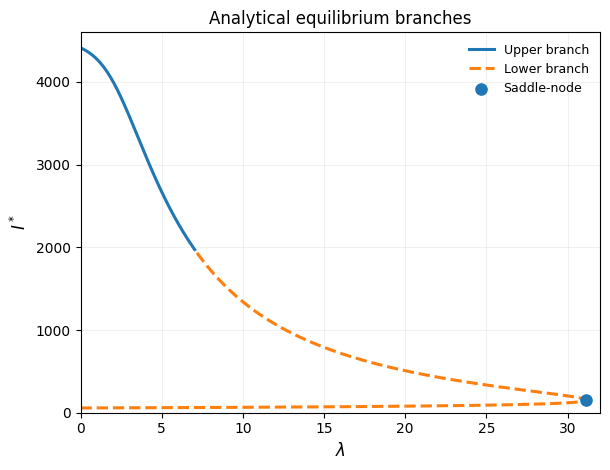

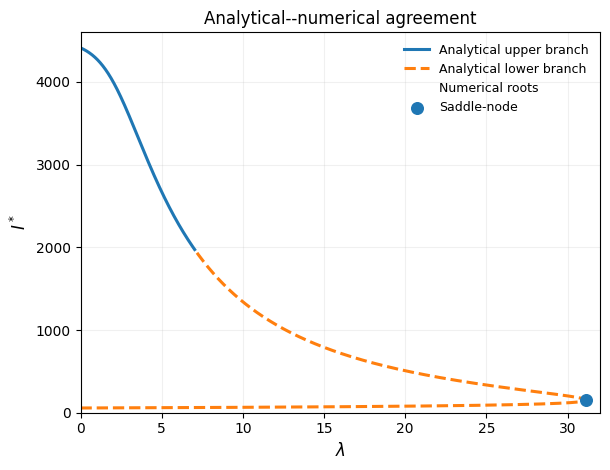

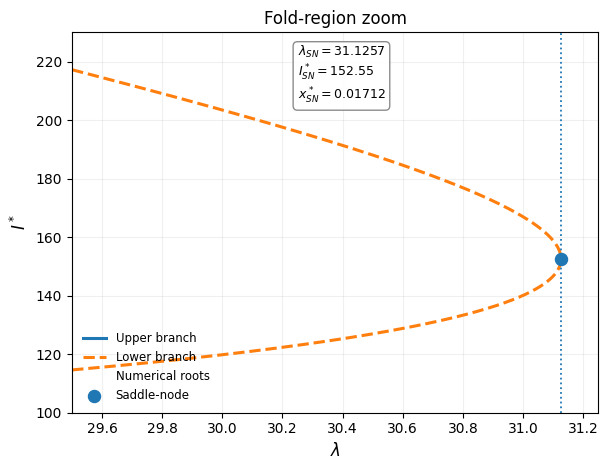

In [ ]:
# ============================================================
# Publication-quality figures saved separately
# ============================================================

# ============================================================
# FIGURE (a): Analytical equilibrium branches
# ============================================================

fig, ax = plt.subplots(figsize=(6.2, 4.8))

ax.plot(
    branch_high[:, 0],
    branch_high[:, 1],
    linewidth=2.2,
    label="Upper branch",
)

ax.plot(
    branch_low[:, 0],
    branch_low[:, 1],
    linewidth=2.2,
    linestyle="--",
    label="Lower branch",
)

ax.scatter(
    [lambda_SN],
    [I_SN],
    s=65,
    zorder=6,
    label="Saddle-node",
)

ax.set_xlabel(r"$\lambda$", fontsize=12)
ax.set_ylabel(r"$I^*$", fontsize=12)

ax.set_title(
    "Analytical equilibrium branches",
    fontsize=12,
)

ax.set_xlim(0, 32)
ax.set_ylim(0, 4600)

ax.legend(
    frameon=False,
    fontsize=9,
)

ax.grid(alpha=0.18)
ax.tick_params(axis="both", labelsize=10)

fig.tight_layout()

fig.savefig(
    "bif_a.png",
    dpi=600,
    bbox_inches="tight",
)

fig.savefig(
    "bif_a.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ============================================================
# FIGURE (b): Analytical--numerical agreement
# ============================================================

fig, ax = plt.subplots(figsize=(6.2, 4.8))

ax.plot(
    branch_high[:, 0],
    branch_high[:, 1],
    linewidth=2.2,
    label="Analytical upper branch",
)

ax.plot(
    branch_low[:, 0],
    branch_low[:, 1],
    linewidth=2.2,
    linestyle="--",
    label="Analytical lower branch",
)

if len(num_high):
    ax.scatter(
        num_high[:, 0],
        num_high[:, 1],
        s=34,
        marker="o",
        facecolors="none",
        linewidths=1.2,
        zorder=5,
        label="Numerical roots",
    )

if len(num_low):
    ax.scatter(
        num_low[:, 0],
        num_low[:, 1],
        s=34,
        marker="o",
        facecolors="none",
        linewidths=1.2,
        zorder=5,
    )

ax.scatter(
    [lambda_SN],
    [I_SN],
    s=70,
    zorder=7,
    label="Saddle-node",
)

ax.set_xlabel(r"$\lambda$", fontsize=12)
ax.set_ylabel(r"$I^*$", fontsize=12)

ax.set_title(
    "Analytical--numerical agreement",
    fontsize=12,
)

ax.set_xlim(0, 32)
ax.set_ylim(0, 4600)

ax.legend(
    frameon=False,
    fontsize=9,
)

ax.grid(alpha=0.18)
ax.tick_params(axis="both", labelsize=10)

fig.tight_layout()

fig.savefig(
    "bif_b.png",
    dpi=600,
    bbox_inches="tight",
)

fig.savefig(
    "bif_b.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ============================================================
# FIGURE (c): Fold-region zoom
# ============================================================

fig, ax = plt.subplots(figsize=(6.2, 4.8))

mask_high = (
    (branch_high[:, 0] >= 29.5)
    & (branch_high[:, 0] <= 31.25)
    & (branch_high[:, 1] >= 100)
    & (branch_high[:, 1] <= 230)
)

mask_low = (
    (branch_low[:, 0] >= 29.5)
    & (branch_low[:, 0] <= 31.25)
    & (branch_low[:, 1] >= 100)
    & (branch_low[:, 1] <= 230)
)

ax.plot(
    branch_high[mask_high, 0],
    branch_high[mask_high, 1],
    linewidth=2.2,
    label="Upper branch",
)

ax.plot(
    branch_low[mask_low, 0],
    branch_low[mask_low, 1],
    linewidth=2.2,
    linestyle="--",
    label="Lower branch",
)

if len(num_high):
    mask_num_high = (
        (num_high[:, 0] >= 29.5)
        & (num_high[:, 0] <= 31.25)
        & (num_high[:, 1] >= 100)
        & (num_high[:, 1] <= 230)
    )

    ax.scatter(
        num_high[mask_num_high, 0],
        num_high[mask_num_high, 1],
        s=42,
        marker="o",
        facecolors="none",
        linewidths=1.3,
        zorder=5,
        label="Numerical roots",
    )

if len(num_low):
    mask_num_low = (
        (num_low[:, 0] >= 29.5)
        & (num_low[:, 0] <= 31.25)
        & (num_low[:, 1] >= 100)
        & (num_low[:, 1] <= 230)
    )

    ax.scatter(
        num_low[mask_num_low, 0],
        num_low[mask_num_low, 1],
        s=42,
        marker="o",
        facecolors="none",
        linewidths=1.3,
        zorder=5,
    )

ax.scatter(
    [lambda_SN],
    [I_SN],
    s=75,
    zorder=7,
    label="Saddle-node",
)

ax.axvline(
    lambda_SN,
    linestyle=":",
    linewidth=1.3,
)

ax.annotate(
    (
        rf"$\lambda_{{SN}}={lambda_SN:.4f}$"
        "\n"
        rf"$I^*_{{SN}}={I_SN:.2f}$"
        "\n"
        rf"$x^*_{{SN}}={x_SN:.5f}$"
    ),
    xy=(lambda_SN, I_SN),
    xytext=(30.25, 207),
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="0.5",
        alpha=0.9,
    ),
)

ax.set_xlabel(r"$\lambda$", fontsize=12)
ax.set_ylabel(r"$I^*$", fontsize=12)

ax.set_title(
    "Fold-region zoom",
    fontsize=12,
)

ax.set_xlim(29.5, 31.25)
ax.set_ylim(100, 230)

ax.legend(
    frameon=False,
    fontsize=8.5,
    loc="lower left",
)

ax.grid(alpha=0.18)
ax.tick_params(axis="both", labelsize=10)

fig.tight_layout()

fig.savefig(
    "bif_c.png",
    dpi=600,
    bbox_inches="tight",
)

fig.savefig(
    "bif_c.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [13]:

import numpy as np
from scipy.optimize import brentq, root
from scipy.special import expit
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt

# ============================================================
# TWO-PARAMETER (Theta, Tc) EQUILIBRIUM MAP CALCULATION
# ============================================================

# Baseline model parameters
beta = 0.6
gamma = 0.2
sigma = 0.25
phi = 0.005
epsilon = 0.8
omega_V = 1 / 365
omega_N = 1 / 730
k = 10.0
mu = 0.05
N = 1_000_000

a = 1 + gamma / sigma + gamma / omega_N
b = gamma * (1 / omega_V - 1 / omega_N)
q = gamma / ((1 - epsilon) * beta) - 1

# Normalized endemic-equilibrium quadratic
def coefficients(x):
    H = a + b * x
    A = beta * H
    B = phi * x * H + gamma - beta
    C = phi * x * q
    return A, B, C

def discriminant(x):
    A, B, C = coefficients(x)
    return B**2 - 4 * A * C

# Coupled saddle-node conditions
def fold_equations(z, Tc):
    i, x = z

    if not (i > 0 and 0 < x < 1):
        return [1e3 + abs(i), 1e3 + abs(x)]

    A, B, C = coefficients(x)

    Q = (A * i + B) * i + C
    Qi = 2 * A * i + B

    Qx = (
        beta * b * i**2
        + phi * (a + 2 * b * x) * i
        + phi * q
    )

    L = k * Tc + np.log(x / (1 - x))

    # Equivalent, scaled fold condition
    G = i * Qi + x * (1 - x) * L * Qx

    return [Q, G]

# ------------------------------------------------------------
# Starting point of the fold boundary
# ------------------------------------------------------------

Tc_start = brentq(
    lambda tc: discriminant(expit(-k * tc)),
    0.20,
    0.30,
    xtol=1e-14
)

x_start = expit(-k * Tc_start)
A0, B0, _ = coefficients(x_start)
i_start = -B0 / (2 * A0)

# ------------------------------------------------------------
# Continue the fold boundary over Tc
# ------------------------------------------------------------

Tc_fold = np.linspace(Tc_start, 0.80, 350)
Theta_fold = np.empty_like(Tc_fold)

guess = np.array([i_start, x_start])

for j, tc in enumerate(Tc_fold):
    if j == 0:
        i, x = guess
    else:
        sol = root(
            fold_equations,
            guess,
            args=(tc,),
            tol=1e-11
        )
        i, x = sol.x

    residual = np.linalg.norm(
        fold_equations([i, x], tc)
    )

    if not (i > 0 and 0 < x < 1 and residual < 1e-9):
        raise RuntimeError(
            f"Fold calculation failed at Tc={tc}"
        )

    L = k * tc + np.log(x / (1 - x))
    Theta_fold[j] = L / i

    guess = np.array([i, x])

# ------------------------------------------------------------
# Refined saddle-node at Tc = 0.5
# ------------------------------------------------------------

sol_base = root(
    fold_equations,
    [0.00015255, 0.017118],
    args=(0.5,),
    tol=1e-12
)

assert np.linalg.norm(
    fold_equations(sol_base.x, 0.5)
) < 1e-10

i_sn, x_sn = sol_base.x

Theta_SN_exact = (
    k * 0.5 + np.log(x_sn / (1 - x_sn))
) / i_sn

lambda_sn = mu * Theta_SN_exact / k

Theta_baseline = k * 0.5 / mu
Tc_baseline = 0.5

# ------------------------------------------------------------
# Parameter-plane grid and equilibrium classification
# ------------------------------------------------------------

Theta_values = np.logspace(
    0, np.log10(2e5), 220
)

Tc_values = np.linspace(
    0.20, 0.80, 180
)

Theta_grid, Tc_grid = np.meshgrid(
    Theta_values, Tc_values
)

Theta_critical_by_Tc = np.interp(
    Tc_values,
    Tc_fold,
    Theta_fold,
    left=0.0
)

equilibrium_count = np.where(
    (Tc_grid >= Tc_start)
    & (Theta_grid < Theta_critical_by_Tc[:, None]),
    2,
    0
)

# ------------------------------------------------------------
# Independent coupled-equation checks
# ------------------------------------------------------------

def direct_count(Theta, Tc):
    infection_grid = np.linspace(0, 0.02, 15001)
    x = expit(Theta * infection_grid - k * Tc)

    A, B, C = coefficients(x)
    f = (A * infection_grid + B) * infection_grid + C

    return int(np.count_nonzero(
        f[:-1] * f[1:] < 0
    ))

checks = [
    (100, 0.5, 2),
    (10000, 0.5, 0),
    (100, 0.3, 2),
    (1000, 0.3, 0),
    (100, 0.2, 0),
    (10000, 0.7, 2),
    (100000, 0.7, 0)
]

for th, tc, expected in checks:
    actual = direct_count(th, tc)
    assert actual == expected, (
        f"Root-count mismatch at Theta={th}, Tc={tc}"
    )

assert abs(Theta_SN_exact - 6225.15) < 0.02
assert abs(lambda_sn - 31.125727294988) < 1e-7

print("Parameter-plane calculation completed.")
print(f"I_SN = {i_sn * N:.9f}")
print(f"Theta_SN = {Theta_SN_exact:.9f}")
print(f"lambda_SN = {lambda_sn:.12f}")
print("Independent root-count checks: PASSED")
print(
    "Equilibrium counts:",
    np.unique(equilibrium_count)
)


Parameter-plane calculation completed.
I_SN = 152.550043044
Theta_SN = 6225.145458998
lambda_SN = 31.125727294988
Independent root-count checks: PASSED
Equilibrium counts: [0 2]


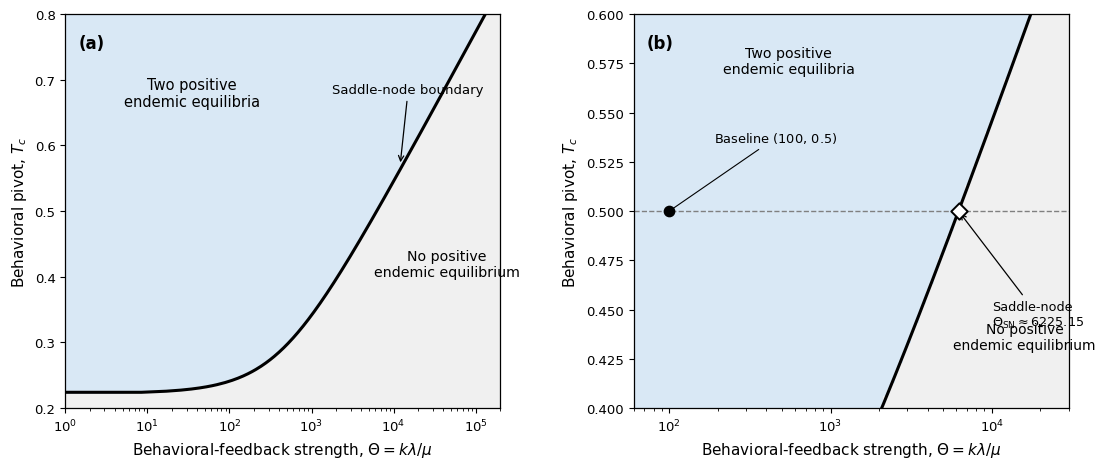

In [14]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt

# ============================================================
# TWO-PANEL PUBLICATION FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.2, 4.8)
)

ax1, ax2 = axes

# ------------------------------------------------------------
# Region colors
# ------------------------------------------------------------

region_cmap = ListedColormap([
    "#f0f0f0",   # 0 positive endemic equilibria
    "#d9e8f5"    # 2 positive endemic equilibria
])

region_norm = BoundaryNorm(
    [-0.5, 0.5, 2.5],
    region_cmap.N
)

# ============================================================
# PANEL (a): Full parameter plane
# ============================================================

ax1.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

ax1.plot(
    Theta_fold,
    Tc_fold,
    color="black",
    linewidth=2.2,
    zorder=5
)

# Direct region labels
ax1.text(
    35,
    0.68,
    "Two positive\nendemic equilibria",
    ha="center",
    va="center",
    fontsize=10.5
)

ax1.text(
    4.5e4,
    0.42,
    "No positive\nendemic equilibrium",
    ha="center",
    va="center",
    fontsize=10.2
)

# Boundary label
ax1.annotate(
    "Saddle-node boundary",
    xy=(1.2e4, 0.57),
    xytext=(1.8e3, 0.68),
    fontsize=9.5,
    ha="left",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=0.9,
        color="black"
    )
)

ax1.set_xscale("log")

ax1.set_xlim(
    1,
    2e5
)

ax1.set_ylim(
    0.20,
    0.80
)

ax1.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=11
)

ax1.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=11
)

ax1.tick_params(
    axis="both",
    labelsize=9.5
)

ax1.text(
    0.03,
    0.95,
    "(a)",
    transform=ax1.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)

# ============================================================
# PANEL (b): Zoom around T_c = 0.5
# ============================================================

ax2.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

ax2.plot(
    Theta_fold,
    Tc_fold,
    color="black",
    linewidth=2.2,
    zorder=5
)

# Horizontal reference line at T_c = 0.5
ax2.axhline(
    0.5,
    linestyle="--",
    linewidth=1.0,
    color="gray"
)

# Baseline point
ax2.scatter(
    Theta_baseline,
    Tc_baseline,
    s=55,
    color="black",
    marker="o",
    zorder=7
)

ax2.annotate(
    r"Baseline $(100,\,0.5)$",
    xy=(Theta_baseline, Tc_baseline),
    xytext=(190, 0.535),
    textcoords="data",
    fontsize=9.3,
    ha="left",
    arrowprops=dict(
        arrowstyle="-",
        linewidth=0.8,
        color="black"
    )
)

# Exact saddle-node point
ax2.scatter(
    Theta_SN_exact,
    0.5,
    s=70,
    facecolor="white",
    edgecolor="black",
    linewidth=1.4,
    marker="D",
    zorder=8
)

ax2.annotate(
    r"Saddle-node"
    "\n"
    r"$\Theta_{\rm SN}\approx6225.15$",
    xy=(Theta_SN_exact, 0.5),
    xytext=(1.0e4, 0.455),
    textcoords="data",
    fontsize=9.2,
    ha="left",
    va="top",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=0.9,
        color="black"
    )
)

# Region labels in zoom
ax2.text(
    550,
    0.57,
    "Two positive\nendemic equilibria",
    fontsize=10.2,
    ha="center"
)

ax2.text(
    1.6e4,
    0.43,
    "No positive\nendemic equilibrium",
    fontsize=10.0,
    ha="center"
)

ax2.set_xscale("log")

# Zoomed range chosen to show both baseline and fold
ax2.set_xlim(
    60,
    3e4
)

ax2.set_ylim(
    0.40,
    0.60
)

ax2.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=11
)

ax2.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=11
)

ax2.tick_params(
    axis="both",
    labelsize=9.5
)

ax2.text(
    0.03,
    0.95,
    "(b)",
    transform=ax2.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)

# ------------------------------------------------------------
# Overall cleanup
# ------------------------------------------------------------

for ax in axes:
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)

fig.tight_layout(
    w_pad=2.6
)

fig.savefig(
    "theta_Tc_two_panel_publication.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "theta_Tc_two_panel_publication.pdf",
    bbox_inches="tight"
)

plt.show()

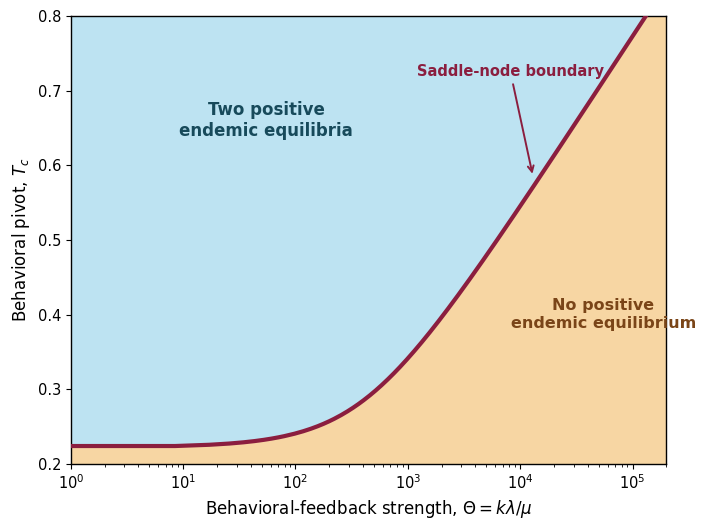

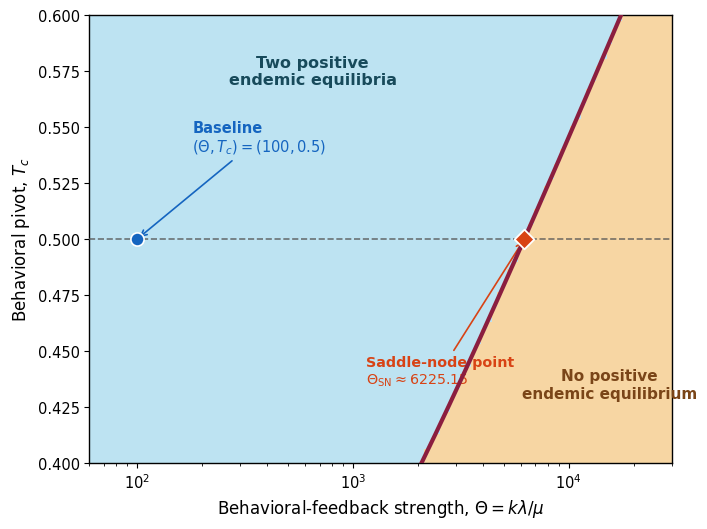

In [15]:
# ============================================================
# CLEAN PUBLICATION FIGURES — TWO SEPARATE IMAGES
# ============================================================

# Colors
COLOR_TWO = "#BDE3F2"       # light cyan-blue: 2 equilibria
COLOR_ZERO = "#F7D6A3"      # light warm orange: 0 equilibria
COLOR_BOUNDARY = "#8B1E3F"  # dark burgundy
COLOR_BASELINE = "#1565C0"  # blue
COLOR_FOLD = "#D84315"      # burnt orange
COLOR_REFERENCE = "#555555"

region_cmap = ListedColormap([
    COLOR_ZERO,
    COLOR_TWO
])

region_norm = BoundaryNorm(
    [-0.5, 0.5, 2.5],
    region_cmap.N
)


# ============================================================
# FIGURE 1: GLOBAL TWO-PARAMETER MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.2, 5.4)
)

# Parameter regions
ax.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

# Saddle-node boundary
ax.plot(
    Theta_fold,
    Tc_fold,
    color=COLOR_BOUNDARY,
    linewidth=3.0,
    zorder=5
)

# -----------------------------
# Region labels
# -----------------------------

ax.text(
    55,
    0.66,
    "Two positive\nendemic equilibria",
    fontsize=12,
    fontweight="bold",
    ha="center",
    va="center",
    color="#174A5B"
)

ax.text(
    5.5e4,
    0.40,
    "No positive\nendemic equilibrium",
    fontsize=11.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="#7A4518"
)

# -----------------------------
# Boundary annotation
# -----------------------------

ax.annotate(
    "Saddle-node boundary",
    xy=(1.3e4, 0.585),
    xytext=(1.2e3, 0.72),
    fontsize=10.5,
    fontweight="bold",
    color=COLOR_BOUNDARY,
    ha="left",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_BOUNDARY,
        linewidth=1.4
    )
)

# -----------------------------
# Axes
# -----------------------------

ax.set_xscale("log")

ax.set_xlim(
    1,
    2e5
)

ax.set_ylim(
    0.20,
    0.80
)

ax.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=12
)

ax.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=12
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10.5
)

# Clean frame
for spine in ax.spines.values():
    spine.set_linewidth(1.0)

ax.grid(False)

fig.tight_layout()

fig.savefig(
    "theta_Tc_global_map.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "theta_Tc_global_map.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: ZOOM AROUND BASELINE AND T_c = 0.5 FOLD
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.2, 5.4)
)

# Parameter regions
ax.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

# Saddle-node boundary
ax.plot(
    Theta_fold,
    Tc_fold,
    color=COLOR_BOUNDARY,
    linewidth=3.0,
    zorder=5
)

# -----------------------------
# T_c = 0.5 reference line
# -----------------------------

ax.axhline(
    0.5,
    color=COLOR_REFERENCE,
    linestyle="--",
    linewidth=1.2,
    alpha=0.8,
    zorder=3
)

# -----------------------------
# Baseline point
# -----------------------------

ax.scatter(
    Theta_baseline,
    Tc_baseline,
    s=90,
    color=COLOR_BASELINE,
    edgecolor="white",
    linewidth=1.2,
    marker="o",
    zorder=8
)

ax.annotate(
    r"Baseline"
    "\n"
    r"$(\Theta,T_c)=(100,0.5)$",
    xy=(
        Theta_baseline,
        Tc_baseline
    ),
    xytext=(
        180,
        0.545
    ),
    textcoords="data",
    fontsize=10.5,
    fontweight="bold",
    color=COLOR_BASELINE,
    ha="left",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_BASELINE,
        linewidth=1.2
    )
)

# -----------------------------
# Exact saddle-node point
# -----------------------------

ax.scatter(
    Theta_SN_exact,
    0.5,
    s=100,
    facecolor=COLOR_FOLD,
    edgecolor="white",
    linewidth=1.3,
    marker="D",
    zorder=9
)

# Moved farther left/down to avoid crowding the boundary
ax.annotate(
    r"Saddle-node point"
    "\n"
    r"$\Theta_{\rm SN}\approx6225.15$",
    xy=(
        Theta_SN_exact,
        0.5
    ),
    xytext=(
        1.15e3,
        0.448
    ),
    textcoords="data",
    fontsize=10.3,
    fontweight="bold",
    color=COLOR_FOLD,
    ha="left",
    va="top",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_FOLD,
        linewidth=1.2
    )
)

# -----------------------------
# Region labels
# -----------------------------

ax.text(
    650,
    0.575,
    "Two positive\nendemic equilibria",
    fontsize=11.5,
    fontweight="bold",
    color="#174A5B",
    ha="center",
    va="center"
)

ax.text(
    1.55e4,
    0.435,
    "No positive\nendemic equilibrium",
    fontsize=11.0,
    fontweight="bold",
    color="#7A4518",
    ha="center",
    va="center"
)

# -----------------------------
# Axes
# -----------------------------

ax.set_xscale("log")

ax.set_xlim(
    60,
    3e4
)

ax.set_ylim(
    0.40,
    0.60
)

ax.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=12
)

ax.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=12
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10.5
)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

ax.grid(False)

fig.tight_layout()

fig.savefig(
    "theta_Tc_zoom_map.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "theta_Tc_zoom_map.pdf",
    bbox_inches="tight"
)

plt.show()

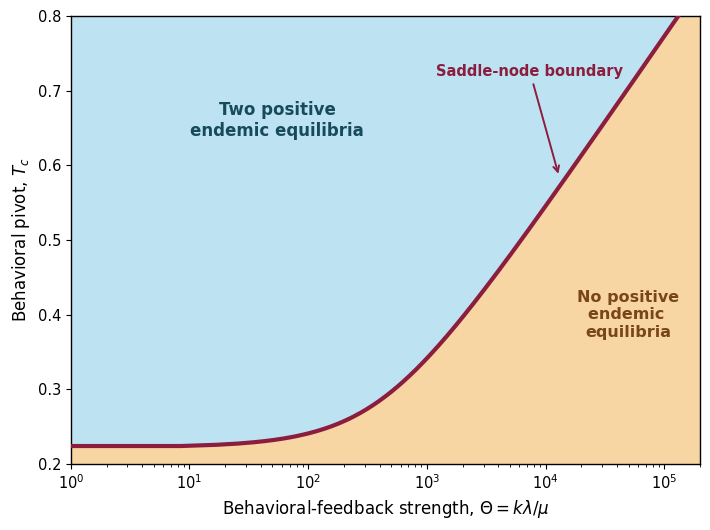

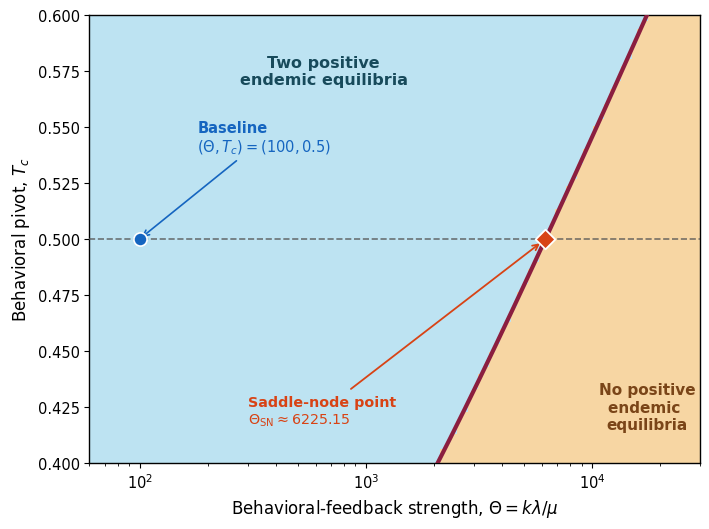

In [16]:
# ============================================================
# CLEAN PUBLICATION FIGURES — TWO SEPARATE IMAGES
# ============================================================

# Colors
COLOR_TWO = "#BDE3F2"       # light cyan-blue: 2 equilibria
COLOR_ZERO = "#F7D6A3"      # light warm orange: 0 equilibria
COLOR_BOUNDARY = "#8B1E3F"  # dark burgundy
COLOR_BASELINE = "#1565C0"  # blue
COLOR_FOLD = "#D84315"      # burnt orange
COLOR_REFERENCE = "#555555"

region_cmap = ListedColormap([
    COLOR_ZERO,
    COLOR_TWO
])

region_norm = BoundaryNorm(
    [-0.5, 0.5, 2.5],
    region_cmap.N
)


# ============================================================
# FIGURE 1: GLOBAL TWO-PARAMETER MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.2, 5.4)
)

# Parameter regions
ax.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

# Saddle-node boundary
ax.plot(
    Theta_fold,
    Tc_fold,
    color=COLOR_BOUNDARY,
    linewidth=3.0,
    zorder=5
)

# ------------------------------------------------------------
# Region labels
# ------------------------------------------------------------

ax.text(
    55,
    0.66,
    "Two positive\nendemic equilibria",
    fontsize=12,
    fontweight="bold",
    ha="center",
    va="center",
    color="#174A5B"
)

ax.text(
    5.0e4,
    0.40,
    "No positive\nendemic \nequilibria",
    fontsize=11.5,
    fontweight="bold",
    ha="center",
    va="center",
    color="#7A4518"
)

# ------------------------------------------------------------
# Saddle-node boundary annotation
# ------------------------------------------------------------

ax.annotate(
    "Saddle-node boundary",
    xy=(1.3e4, 0.585),
    xytext=(1.2e3, 0.72),
    fontsize=10.5,
    fontweight="bold",
    color=COLOR_BOUNDARY,
    ha="left",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_BOUNDARY,
        linewidth=1.4
    )
)

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xscale("log")

ax.set_xlim(
    1,
    2e5
)

ax.set_ylim(
    0.20,
    0.80
)

ax.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=12
)

ax.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=12
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10.5
)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

ax.grid(False)

fig.tight_layout()

fig.savefig(
    "theta_Tc_global_map.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "theta_Tc_global_map.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: ZOOM AROUND BASELINE AND T_c = 0.5 FOLD
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.2, 5.4)
)

# Parameter regions
ax.pcolormesh(
    Theta_values,
    Tc_values,
    equilibrium_count,
    cmap=region_cmap,
    norm=region_norm,
    shading="nearest",
    rasterized=True
)

# Saddle-node boundary
ax.plot(
    Theta_fold,
    Tc_fold,
    color=COLOR_BOUNDARY,
    linewidth=3.0,
    zorder=5
)

# ------------------------------------------------------------
# Horizontal reference line at T_c = 0.5
# ------------------------------------------------------------

ax.axhline(
    0.5,
    color=COLOR_REFERENCE,
    linestyle="--",
    linewidth=1.2,
    alpha=0.8,
    zorder=3
)

# ------------------------------------------------------------
# Baseline point
# ------------------------------------------------------------

ax.scatter(
    Theta_baseline,
    Tc_baseline,
    s=90,
    color=COLOR_BASELINE,
    edgecolor="white",
    linewidth=1.2,
    marker="o",
    zorder=8
)

ax.annotate(
    r"Baseline"
    "\n"
    r"$(\Theta,T_c)=(100,0.5)$",
    xy=(
        Theta_baseline,
        Tc_baseline
    ),
    xytext=(
        180,
        0.545
    ),
    textcoords="data",
    fontsize=10.5,
    fontweight="bold",
    color=COLOR_BASELINE,
    ha="left",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_BASELINE,
        linewidth=1.2
    )
)

# ------------------------------------------------------------
# Exact saddle-node point
# ------------------------------------------------------------

ax.scatter(
    Theta_SN_exact,
    0.5,
    s=100,
    facecolor=COLOR_FOLD,
    edgecolor="white",
    linewidth=1.3,
    marker="D",
    zorder=9
)

# ------------------------------------------------------------
# Saddle-node point annotation
#
# Moved clearly farther LEFT and DOWN so that:
#   1. it does not crowd the saddle-node boundary,
#   2. it does not overlap the zero-equilibrium label,
#   3. the arrow approaches the fold point cleanly.
# ------------------------------------------------------------

ax.annotate(
    r"Saddle-node point"
    "\n"
    r"$\Theta_{\rm SN}\approx6225.15$",
    xy=(
        Theta_SN_exact,
        0.5
    ),
    xytext=(
    300,
    0.423
),
    textcoords="data",
    fontsize=10.3,
    fontweight="bold",
    color=COLOR_FOLD,
    ha="left",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        color=COLOR_FOLD,
        linewidth=1.3,
        shrinkA=4,
        shrinkB=5
    )
)

# ------------------------------------------------------------
# Region labels
# ------------------------------------------------------------

ax.text(
    650,
    0.575,
    "Two positive\nendemic equilibria",
    fontsize=11.5,
    fontweight="bold",
    color="#174A5B",
    ha="center",
    va="center"
)

ax.text(
    1.75e4,
    0.425,
    "No positive\nendemic \nequilibria",
    fontsize=11.0,
    fontweight="bold",
    color="#7A4518",
    ha="center",
    va="center"
)

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xscale("log")

ax.set_xlim(
    60,
    3e4
)

ax.set_ylim(
    0.40,
    0.60
)

ax.set_xlabel(
    r"Behavioral-feedback strength, "
    r"$\Theta=k\lambda/\mu$",
    fontsize=12
)

ax.set_ylabel(
    r"Behavioral pivot, $T_c$",
    fontsize=12
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10.5
)

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

ax.grid(False)

fig.tight_layout()

fig.savefig(
    "theta_Tc_zoom_map.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "theta_Tc_zoom_map.pdf",
    bbox_inches="tight"
)

plt.show()

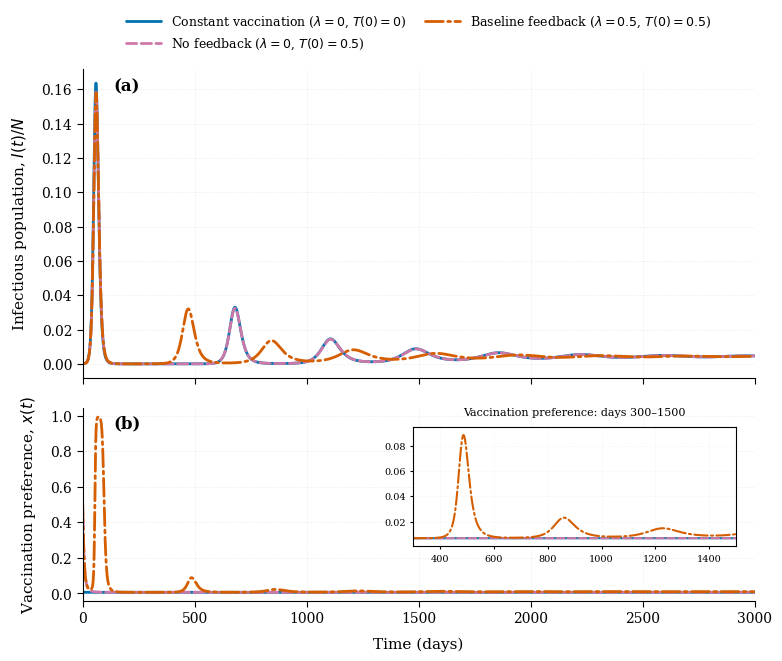


NO-FEEDBACK AND BASELINE COMPARISON

Constant vaccination ($\lambda=0$, $T(0)=0$)
------------------------------------------------------------
I(365)   = 0.149113
I(3000)  = 4639.252033
x(0)     = 0.00669285
x(3000)  = 0.00669285

No feedback ($\lambda=0$, $T(0)=0.5$)
------------------------------------------------------------
I(365)   = 0.175570
I(3000)  = 4642.439770
x(0)     = 0.50000000
x(3000)  = 0.00669285

Baseline feedback ($\lambda=0.5$, $T(0)=0.5$)
------------------------------------------------------------
I(365)   = 322.684551
I(3000)  = 4416.783053
x(0)     = 0.50000000
x(3000)  = 0.01032492

Figures saved successfully.


In [17]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# =====================================================
# 1. BASELINE PARAMETERS
# =====================================================

N = 1_000_000

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2
omega_V = 1 / 365
omega_N = 1 / 730
mu = 0.05
k = 10
T_c = 0.5


# =====================================================
# 2. VACCINATION PREFERENCE
# =====================================================

def vaccination_preference(T):
    return 1 / (1 + np.exp(-k * (T - T_c)))


# =====================================================
# 3. SEVEN-DIMENSIONAL EPIDEMIC MODEL
# =====================================================

def epidemic_model(t, y, lam):

    S, V, E, I, R_N, R_V, T = y

    x = vaccination_preference(T)

    dS = (
        -beta * S * I / N
        - phi * x * S
        + omega_N * R_N
        + omega_V * R_V
    )

    dV = (
        phi * x * S
        - (1 - epsilon) * beta * V * I / N
    )

    dE = (
        beta * S * I / N
        + (1 - epsilon) * beta * V * I / N
        - sigma * E
    )

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omega_N * R_N

    dRV = x * gamma * I - omega_V * R_V

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


# =====================================================
# 4. INITIAL CONDITIONS
# =====================================================

y_initial = np.array([
    999900,  # S(0)
    0,       # V(0)
    0,       # E(0)
    100,     # I(0)
    0,       # R_N(0)
    0,       # R_V(0)
    0.5      # T(0), replaced for each scenario
], dtype=float)

t_eval = np.linspace(0, 3000, 6001)


# =====================================================
# 5. THREE COMPARISON SCENARIOS
# =====================================================

scenarios = [
    {
        "label": r"Constant vaccination ($\lambda=0$, $T(0)=0$)",
        "lam": 0.0,
        "T0": 0.0,
        "color": "#0072B2",
        "style": "-"
    },
    {
        "label": r"No feedback ($\lambda=0$, $T(0)=0.5$)",
        "lam": 0.0,
        "T0": 0.5,
        "color": "#CC79A7",
        "style": "--"
    },
    {
        "label": r"Baseline feedback ($\lambda=0.5$, $T(0)=0.5$)",
        "lam": 0.5,
        "T0": 0.5,
        "color": "#D55E00",
        "style": "-."
    }
]


# =====================================================
# 6. SOLVE THE MODEL
# =====================================================

solutions = {}

for scenario in scenarios:

    y0 = y_initial.copy()
    y0[-1] = scenario["T0"]

    solution = solve_ivp(
        fun=lambda t, y: epidemic_model(
            t, y, scenario["lam"]
        ),
        t_span=(0, 3000),
        y0=y0,
        t_eval=t_eval,
        method="DOP853",
        rtol=2e-10,
        atol=1e-10
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    solutions[scenario["label"]] = solution


# =====================================================
# 7. PUBLICATION-QUALITY FIGURE SETTINGS
# =====================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600,
    "lines.antialiased": True
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(8.0, 7.0),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2, 1.25],
        "hspace": 0.12
    }
)


# =====================================================
# 8. COMMON LINE STYLING
# =====================================================

# Rounded caps and joins help reduce tiny white gaps
# that can appear when curves are rasterized or resized.

line_options = {
    "solid_capstyle": "round",
    "solid_joinstyle": "round",
    "dash_capstyle": "round",
    "dash_joinstyle": "round",
    "antialiased": True,
    "marker": None
}


# =====================================================
# 9. MAIN CURVES
# =====================================================

for scenario in scenarios:

    sol = solutions[scenario["label"]]

    t = sol.t
    I = sol.y[3]
    T = sol.y[6]
    x = vaccination_preference(T)

    # Panel (a): infectious population fraction
    axes[0].plot(
        t,
        I / N,
        color=scenario["color"],
        linestyle=scenario["style"],
        linewidth=2.0,
        label=scenario["label"],
        **line_options
    )

    # Panel (b): vaccination preference
    axes[1].plot(
        t,
        x,
        color=scenario["color"],
        linestyle=scenario["style"],
        linewidth=2.0,
        **line_options
    )


# =====================================================
# 10. AXIS FORMATTING
# =====================================================

for ax in axes:

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.6,
        alpha=0.30
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        direction="out",
        length=4,
        width=0.8
    )

axes[0].set_ylabel(
    r"Infectious population, $I(t)/N$",
    labelpad=9
)

axes[1].set_ylabel(
    r"Vaccination preference, $x(t)$",
    labelpad=9
)

axes[1].set_xlabel(
    "Time (days)",
    labelpad=8
)

axes[0].set_xlim(0, 3000)


# =====================================================
# 11. LEGEND
# =====================================================

axes[0].legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    columnspacing=1.4,
    handlelength=2.8,
    fontsize=9
)


# =====================================================
# 12. PANEL LABELS
# =====================================================

axes[0].text(
    0.045, 0.93,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=12,
    fontweight="bold"
)

axes[1].text(
    0.045, 0.90,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=12,
    fontweight="bold"
)


# =====================================================
# 13. INSET: VACCINATION PREFERENCE, DAYS 300-1500
# =====================================================

ax_inset = inset_axes(
    axes[1],
    width="48%",
    height="62%",
    loc="upper right",
    borderpad=1.5
)

for scenario in scenarios:

    sol = solutions[scenario["label"]]

    t = sol.t
    T = sol.y[6]
    x = vaccination_preference(T)

    ax_inset.plot(
        t,
        x,
        color=scenario["color"],
        linestyle=scenario["style"],
        linewidth=1.5,
        **line_options
    )

ax_inset.set_xlim(300, 1500)

# Determine inset y-limits automatically
inset_values = []

for scenario in scenarios:

    sol = solutions[scenario["label"]]

    mask = (sol.t >= 300) & (sol.t <= 1500)

    inset_values.extend(
        vaccination_preference(
            sol.y[6, mask]
        )
    )

ymin = min(inset_values)
ymax = max(inset_values)
yrange = ymax - ymin

ax_inset.set_ylim(
    max(0, ymin - 0.08 * yrange),
    ymax + 0.08 * yrange
)

ax_inset.set_title(
    "Vaccination preference: days 300–1500",
    fontsize=8,
    pad=8
)

ax_inset.tick_params(
    axis="both",
    labelsize=7,
    direction="out",
    length=2
)

ax_inset.grid(
    True,
    linestyle=":",
    linewidth=0.4,
    alpha=0.25
)


# =====================================================
# 14. SAVE FIGURES
# =====================================================

fig.subplots_adjust(
    left=0.13,
    right=0.97,
    bottom=0.10,
    top=0.86
)

fig.savefig(
    "major1_no_feedback_comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "major1_no_feedback_comparison.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# =====================================================
# 15. PRINT NUMERICAL COMPARISONS
# =====================================================

print("\n" + "=" * 75)
print("NO-FEEDBACK AND BASELINE COMPARISON")
print("=" * 75)

for scenario in scenarios:

    sol = solutions[scenario["label"]]

    I_365 = np.interp(
        365,
        sol.t,
        sol.y[3]
    )

    I_3000 = sol.y[3, -1]

    x_0 = vaccination_preference(
        sol.y[6, 0]
    )

    x_3000 = vaccination_preference(
        sol.y[6, -1]
    )

    print(f"\n{scenario['label']}")
    print("-" * 60)

    print(f"I(365)   = {I_365:.6f}")
    print(f"I(3000)  = {I_3000:.6f}")
    print(f"x(0)     = {x_0:.8f}")
    print(f"x(3000)  = {x_3000:.8f}")

print("\nFigures saved successfully.")


Initial condition  lambda Relative to fold   I(3000)       I(20000)    Tail mean I  Tail range I       T(20000)     x(20000)     Max I  Max x  Final max |dY/dt|
         I0 = 100      25            Below 43.557754      334.08373      333.66957     0.9458786     0.16703883  0.034569186 132379.41      1        0.074546366
         I0 = 100      30            Below 85.952021      184.18642      181.98197     4.5145652      0.1104866  0.019935154 130797.14      1         0.39643225
         I0 = 100      31            Below 130.62148      114.82501      116.88431     3.9566114    0.071219136  0.013548897 130509.01      1         0.38548018
         I0 = 100      32            Above 209.93365     0.50929395      5.2254392      13.64554  0.00034381511 0.0067157468    130229      1          5.2213536
         I0 = 100      40            Above 29.589109 -3.1668761e-12 -1.6551578e-13 7.7000484e-10  3.2864753e-16 0.0066928509 128233.15      1          3.8067564
        I0 = 5000      25         

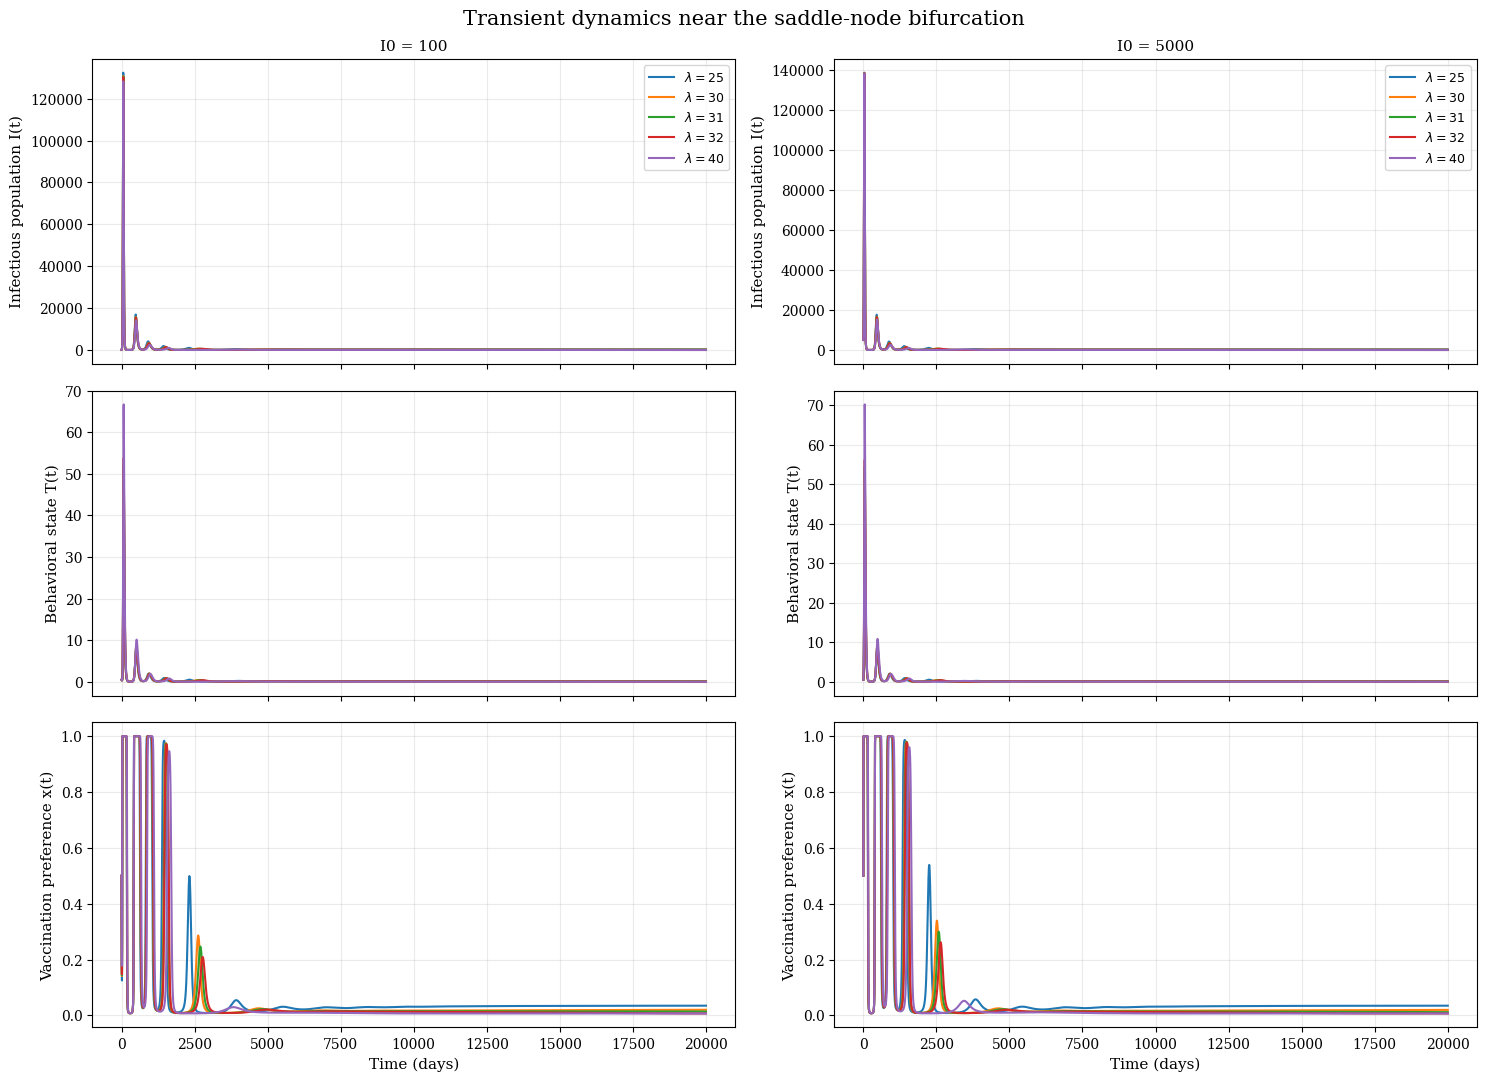

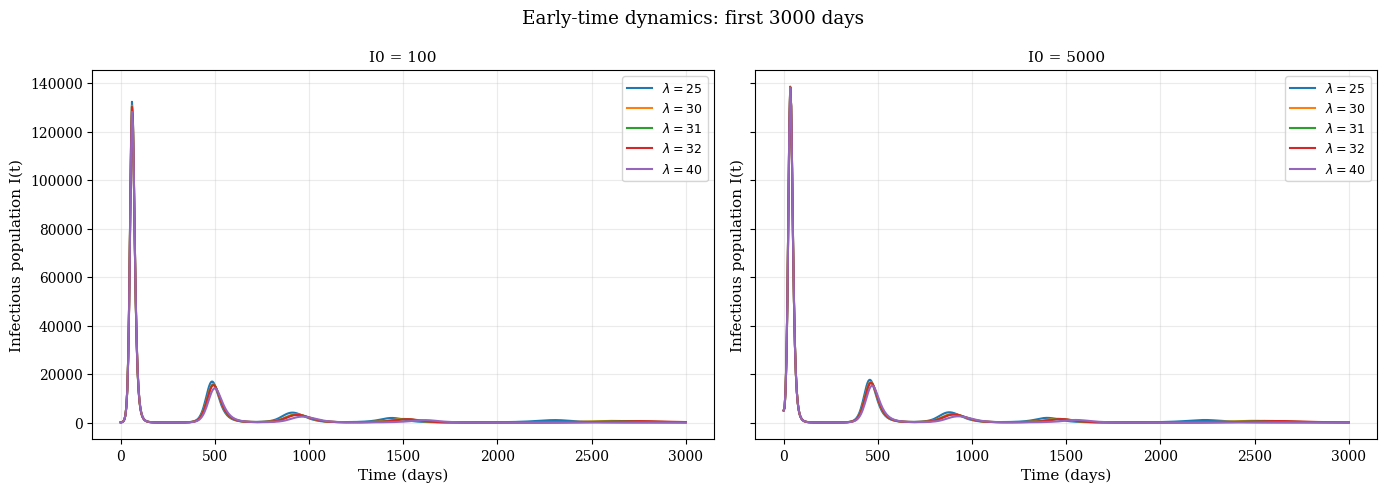

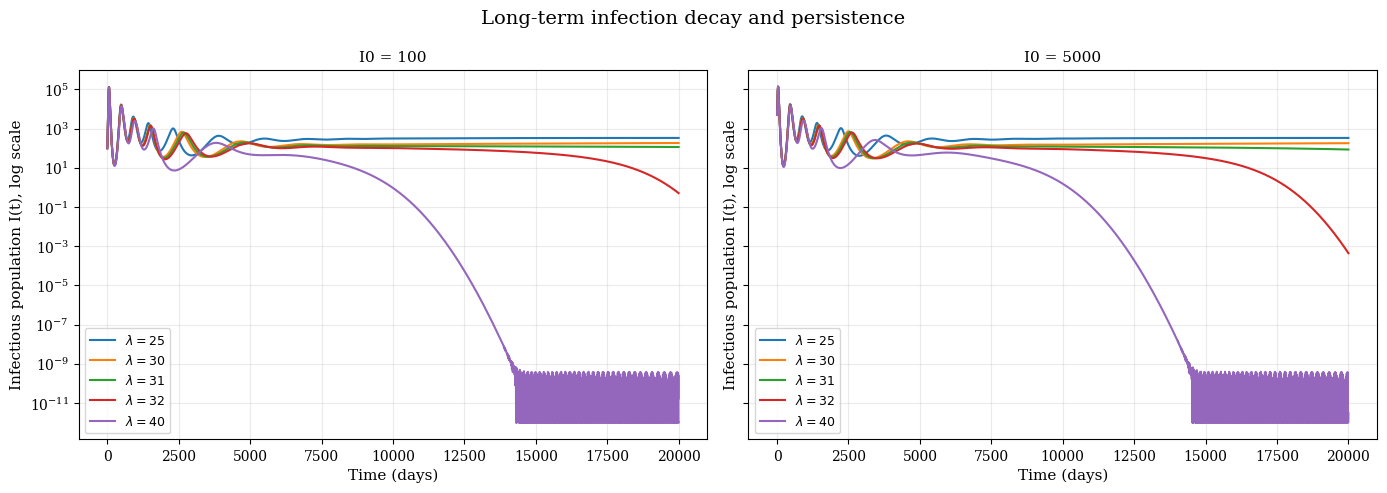


Fold location: 31.1257273
All figures and CSV results saved.


In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit

# ============================================================
# 1. MODEL PARAMETERS
# ============================================================

N = 1_000_000

base = {
    "beta": 0.6,
    "phi": 0.005,
    "eps": 0.8,
    "sigma": 0.25,
    "gamma": 0.2,
    "omegaV": 1 / 365,
    "omegaN": 1 / 730,
    "mu": 0.05,
    "k": 10,
    "Tc": 0.5,
}

lambda_SN = 31.1257273
lambda_values = [25, 30, 31, 32, 40]

# Long horizon to investigate slow transients near the fold
t_end = 20_000
t_eval = np.linspace(0, t_end, 4001)

# ============================================================
# 2. MODEL
# ============================================================

def vaccination_preference(T):
    return expit(base["k"] * (T - base["Tc"]))


def epidemic_model(t, y, lam):
    S, V, E, I, RN, RV, T = y

    beta = base["beta"]
    phi = base["phi"]
    eps = base["eps"]
    sigma = base["sigma"]
    gamma = base["gamma"]
    omegaV = base["omegaV"]
    omegaN = base["omegaN"]
    mu = base["mu"]

    x = vaccination_preference(T)

    dS = (
        -beta * S * I / N
        -phi * x * S
        +omegaN * RN
        +omegaV * RV
    )

    dV = (
        phi * x * S
        -(1 - eps) * beta * V * I / N
    )

    dE = (
        beta * S * I / N
        +(1 - eps) * beta * V * I / N
        -base["sigma"] * E
    )

    dI = base["sigma"] * E - base["gamma"] * I

    dRN = (1 - x) * base["gamma"] * I - omegaN * RN
    dRV = x * base["gamma"] * I - omegaV * RV

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


# ============================================================
# 3. INITIAL CONDITIONS
# ============================================================

# Original manuscript initial condition
initial_conditions = {
    "I0 = 100": [999900, 0, 0, 100, 0, 0, 0.5],

    # Additional initial condition
    "I0 = 5000": [995000, 0, 0, 5000, 0, 0, 0.5],
}

# ============================================================
# 4. RUN SIMULATIONS
# ============================================================

solutions = {}
records = []

for label, y0 in initial_conditions.items():

    for lam in lambda_values:

        sol = solve_ivp(
            epidemic_model,
            (0, t_end),
            y0,
            args=(lam,),
            method="DOP853",
            t_eval=t_eval,
            rtol=1e-9,
            atol=1e-11,
        )

        if not sol.success:
            raise RuntimeError(
                f"Integration failed for {label}, "
                f"lambda={lam}: {sol.message}"
            )

        S, V, E, I, RN, RV, T = sol.y
        x = vaccination_preference(T)

        solutions[(label, lam)] = {
            "t": sol.t,
            "I": I,
            "T": T,
            "x": x,
            "y": sol.y,
        }

        # Mean infection over final 10% of simulation
        tail_start = int(0.9 * len(I))
        tail_I = I[tail_start:]

        # Approximate derivative at the final state
        final_derivative = np.asarray(
            epidemic_model(sol.t[-1], sol.y[:, -1], lam)
        )

        records.append({
            "Initial condition": label,
            "lambda": lam,
            "Relative to fold": (
                "Below" if lam < lambda_SN else "Above"
            ),
            "I(3000)": np.interp(3000, sol.t, I),
            "I(20000)": I[-1],
            "Tail mean I": np.mean(tail_I),
            "Tail range I": np.ptp(tail_I),
            "T(20000)": T[-1],
            "x(20000)": x[-1],
            "Max I": np.max(I),
            "Max x": np.max(x),
            "Final max |dY/dt|": np.max(
                np.abs(final_derivative)
            ),
        })

results = pd.DataFrame(records)

pd.set_option("display.max_columns", None)
print(results.to_string(index=False, float_format="%.8g"))

results.to_csv(
    "near_fold_numerical_results.csv",
    index=False
)

# ============================================================
# 5. FIGURE 1: INFECTION, TRUST, VACCINATION PREFERENCE
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 11),
    sharex=True
)

for j, (label, _) in enumerate(initial_conditions.items()):

    for lam in lambda_values:

        data = solutions[(label, lam)]
        t = data["t"]

        axes[0, j].plot(
            t, data["I"], label=fr"$\lambda={lam}$"
        )
        axes[1, j].plot(t, data["T"])
        axes[2, j].plot(t, data["x"])

    axes[0, j].set_title(label)
    axes[0, j].set_ylabel("Infectious population I(t)")
    axes[1, j].set_ylabel("Behavioral state T(t)")
    axes[2, j].set_ylabel("Vaccination preference x(t)")
    axes[2, j].set_xlabel("Time (days)")

    for row in range(3):
        axes[row, j].grid(alpha=0.25)

    axes[0, j].legend()

fig.suptitle(
    "Transient dynamics near the saddle-node bifurcation",
    fontsize=15
)
fig.tight_layout()

fig.savefig(
    "near_fold_full_trajectories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. FIGURE 2: EARLY-TIME INFECTION DYNAMICS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for j, label in enumerate(initial_conditions):

    for lam in lambda_values:
        data = solutions[(label, lam)]

        mask = data["t"] <= 3000

        axes[j].plot(
            data["t"][mask],
            data["I"][mask],
            label=fr"$\lambda={lam}$"
        )

    axes[j].set_title(label)
    axes[j].set_xlabel("Time (days)")
    axes[j].set_ylabel("Infectious population I(t)")
    axes[j].grid(alpha=0.25)
    axes[j].legend()

fig.suptitle("Early-time dynamics: first 3000 days")
fig.tight_layout()

fig.savefig(
    "near_fold_early_dynamics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. FIGURE 3: LOG-SCALE INFECTION DYNAMICS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for j, label in enumerate(initial_conditions):

    for lam in lambda_values:
        data = solutions[(label, lam)]

        # Clip only for plotting on a logarithmic scale
        I_plot = np.maximum(data["I"], 1e-12)

        axes[j].semilogy(
            data["t"],
            I_plot,
            label=fr"$\lambda={lam}$"
        )

    axes[j].set_title(label)
    axes[j].set_xlabel("Time (days)")
    axes[j].set_ylabel("Infectious population I(t), log scale")
    axes[j].grid(alpha=0.25)
    axes[j].legend()

fig.suptitle(
    "Long-term infection decay and persistence",
    fontsize=14
)
fig.tight_layout()

fig.savefig(
    "near_fold_log_infection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFold location:", lambda_SN)
print("All figures and CSV results saved.")


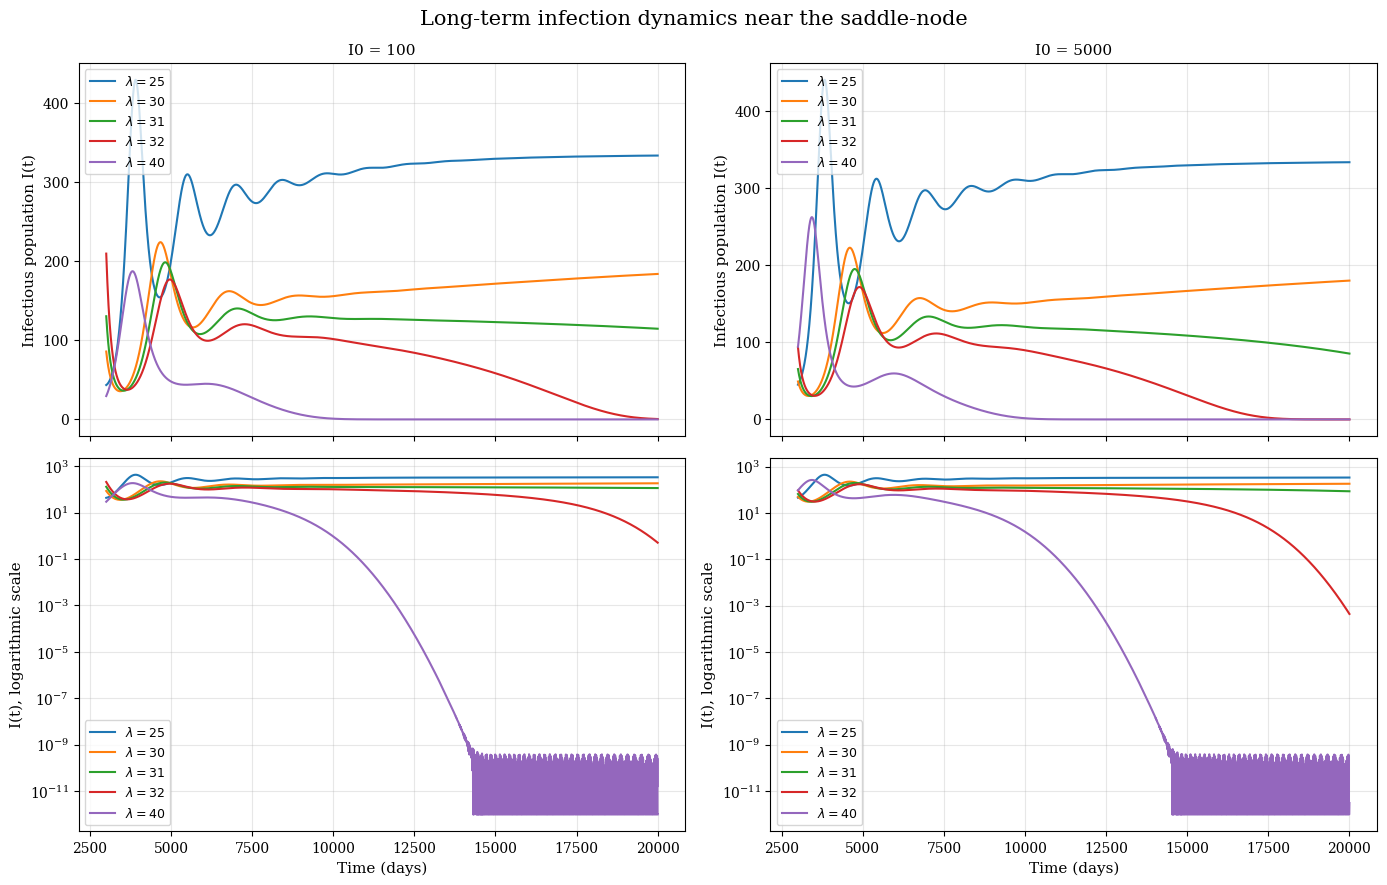

In [19]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharex=True
)

for j, label in enumerate(initial_conditions):

    for lam in lambda_values:
        data = solutions[(label, lam)]
        t = data["t"]
        I = data["I"]

        mask = t >= 3000

        axes[0, j].plot(
            t[mask],
            I[mask],
            label=fr"$\lambda={lam}$"
        )

        axes[1, j].semilogy(
            t[mask],
            np.maximum(I[mask], 1e-12),
            label=fr"$\lambda={lam}$"
        )

    axes[0, j].set_title(label)
    axes[0, j].set_ylabel("Infectious population I(t)")
    axes[1, j].set_ylabel("I(t), logarithmic scale")
    axes[1, j].set_xlabel("Time (days)")

    for row in range(2):
        axes[row, j].grid(alpha=0.3)
        axes[row, j].legend()

fig.suptitle(
    "Long-term infection dynamics near the saddle-node",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [20]:

columns = [
    "Initial condition",
    "lambda",
    "I(3000)",
    "I(20000)",
    "Tail mean I",
    "Tail range I",
    "T(20000)",
    "x(20000)",
    "Final max |dY/dt|",
]

print(
    results[columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.8g}"
    )
)


Initial condition  lambda   I(3000)       I(20000)    Tail mean I  Tail range I       T(20000)     x(20000)  Final max |dY/dt|
         I0 = 100      25 43.557754      334.08373      333.66957     0.9458786     0.16703883  0.034569186        0.074546366
         I0 = 100      30 85.952021      184.18642      181.98197     4.5145652      0.1104866  0.019935154         0.39643225
         I0 = 100      31 130.62148      114.82501      116.88431     3.9566114    0.071219136  0.013548897         0.38548018
         I0 = 100      32 209.93365     0.50929395      5.2254392      13.64554  0.00034381511 0.0067157468          5.2213536
         I0 = 100      40 29.589109 -3.1668761e-12 -1.6551578e-13 7.7000484e-10  3.2864753e-16 0.0066928509          3.8067564
        I0 = 5000      25 45.113937      334.09881      333.69423    0.92209373      0.1670464  0.034571712        0.073399954
        I0 = 5000      30 49.257947      180.32082      177.85477       5.02741     0.10816399  0.019486394    

 lambda Initial condition  Lower equilibrium  Higher equilibrium   I(20000)  Difference from higher  Relative difference (%)
     25          I0 = 100          91.311773          335.088508 334.083733               -1.004775                 0.299854
     25         I0 = 5000          91.311773          335.088508 334.098811               -0.989698                 0.295354
     30          I0 = 100         119.818869          203.456593 184.186416              -19.270177                 9.471395
     30         I0 = 5000         119.818869          203.456593 180.320822              -23.135771                11.371355
     31          I0 = 100         140.106938          166.949505 114.825010              -52.124495                31.221713
     31         I0 = 5000         140.106938          166.949505  85.527596              -81.421909                48.770381


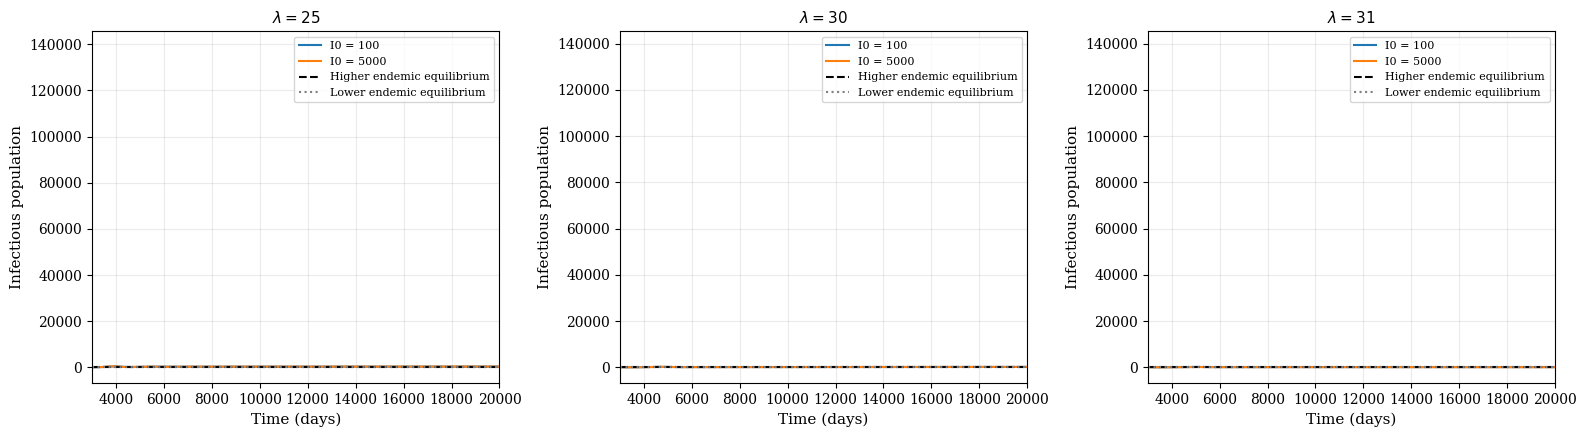

In [21]:

from scipy.optimize import brentq
from scipy.special import expit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Baseline parameters from the manuscript
N = 1_000_000
beta = 0.6
phi = 0.005
eps = 0.8
sigma = 0.25
gamma = 0.2
omegaV = 1 / 365
omegaN = 1 / 730
mu = 0.05
k = 10
Tc = 0.5


def endemic_state(I, lam):
    """Construct a positive endemic equilibrium from I and lambda."""

    T = lam * I / (mu * N)
    x = expit(k * (T - Tc))

    S = (gamma * N / beta) / (
        1 + phi * x * N / (beta * I)
    )

    V = phi * x * S * N / (
        (1 - eps) * beta * I
    )

    E = gamma * I / sigma
    RN = (1 - x) * gamma * I / omegaN
    RV = x * gamma * I / omegaV

    return np.array([S, V, E, I, RN, RV, T]), x


def equilibrium_residual(I, lam):
    """Population conservation residual at an endemic equilibrium."""
    state, _ = endemic_state(I, lam)
    return np.sum(state[:6]) - N


def find_endemic_roots(lam):
    grid = np.geomspace(1e-5, 2e4, 6000)
    values = [
        equilibrium_residual(I, lam)
        for I in grid
    ]

    roots = []

    for j in range(len(grid) - 1):
        if values[j] * values[j + 1] < 0:
            root = brentq(
                equilibrium_residual,
                grid[j],
                grid[j + 1],
                args=(lam,),
                xtol=1e-12
            )

            if not roots or abs(root - roots[-1]) > 1e-5:
                roots.append(root)

    return sorted(roots)


comparison = []

for lam in [25, 30, 31]:

    roots = find_endemic_roots(lam)
    assert len(roots) == 2, (
        f"Expected two endemic roots at lambda={lam}, "
        f"found {roots}"
    )

    lower, higher = roots

    for label in ["I0 = 100", "I0 = 5000"]:
        I_final = solutions[(label, lam)]["I"][-1]

        comparison.append({
            "lambda": lam,
            "Initial condition": label,
            "Lower equilibrium": lower,
            "Higher equilibrium": higher,
            "I(20000)": I_final,
            "Difference from higher": I_final - higher,
            "Relative difference (%)":
                100 * abs(I_final - higher) / higher
        })

comparison_df = pd.DataFrame(comparison)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda z: f"{z:.6f}"
    )
)

# Plot late-time trajectories with equilibrium reference lines
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, lam in zip(axes, [25, 30, 31]):

    lower, higher = find_endemic_roots(lam)

    for label in ["I0 = 100", "I0 = 5000"]:
        data = solutions[(label, lam)]

        ax.plot(
            data["t"],
            data["I"],
            label=label
        )

    ax.axhline(
        higher,
        color="black",
        linestyle="--",
        label="Higher endemic equilibrium"
    )

    ax.axhline(
        lower,
        color="gray",
        linestyle=":",
        label="Lower endemic equilibrium"
    )

    ax.set_xlim(3000, 20000)
    ax.set_title(fr"$\lambda={lam}$")
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Infectious population")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    "near_fold_equilibrium_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


 lambda Initial condition  Lower equilibrium  Higher equilibrium  I(20000)       I(50000)      I(100000)  Distance from higher at 100000
     30          I0 = 100          119.81887           203.45659 184.18642      203.09291      203.45627                   0.00032224898
     30         I0 = 5000          119.81887           203.45659 180.32082      202.99332      203.45618                   0.00041086457
     31          I0 = 100          140.10694            166.9495 114.82501 -1.5062694e-10  4.1752788e-12                        166.9495
     31         I0 = 5000          140.10694            166.9495 85.527596 -6.0334589e-11 -2.4046429e-12                        166.9495


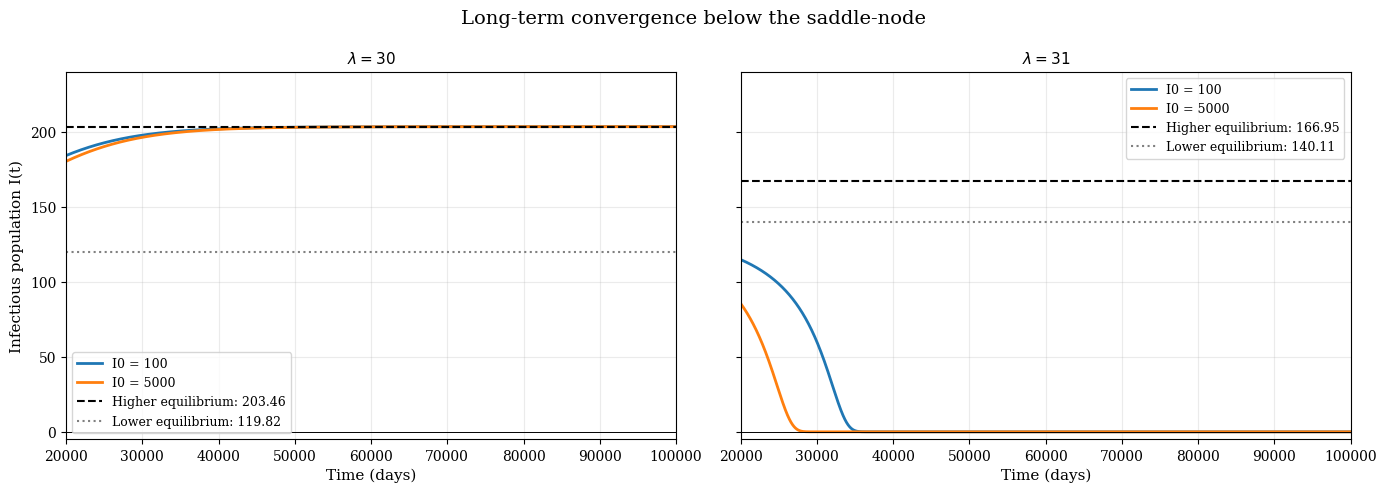

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# =====================================================
# 1. CONTINUE THE EXISTING TRAJECTORIES TO 100,000 DAYS
# =====================================================

lambdas = [30, 31]
initial_labels = ["I0 = 100", "I0 = 5000"]

extended = {}
records = []

for lam in lambdas:
    lower, higher = find_endemic_roots(lam)

    for label in initial_labels:
        previous = solutions[(label, lam)]

        # Start from the full seven-dimensional state at day 20,000
        y_start = previous["y"][:, -1]

        t_new = np.linspace(20000, 100000, 4001)

        sol = solve_ivp(
            epidemic_model,
            (20000, 100000),
            y_start,
            args=(lam,),
            method="DOP853",
            t_eval=t_new,
            rtol=1e-9,
            atol=1e-11,
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        # Combine original and extended trajectories
        t_full = np.concatenate([
            previous["t"],
            sol.t[1:]
        ])

        I_full = np.concatenate([
            previous["I"],
            sol.y[3, 1:]
        ])

        extended[(label, lam)] = {
            "t": t_full,
            "I": I_full,
            "final_state": sol.y[:, -1],
        }

        records.append({
            "lambda": lam,
            "Initial condition": label,
            "Lower equilibrium": lower,
            "Higher equilibrium": higher,
            "I(20000)": np.interp(20000, t_full, I_full),
            "I(50000)": np.interp(50000, t_full, I_full),
            "I(100000)": I_full[-1],
            "Distance from higher at 100000":
                abs(I_full[-1] - higher),
        })

df_extended = pd.DataFrame(records)

print(
    df_extended.to_string(
        index=False,
        float_format=lambda z: f"{z:.8g}"
    )
)

df_extended.to_csv(
    "near_fold_100000_day_comparison.csv",
    index=False
)

# =====================================================
# 2. PLOT WITH CORRECT AXIS LIMITS
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for ax, lam in zip(axes, lambdas):
    lower, higher = find_endemic_roots(lam)

    for label in initial_labels:
        data = extended[(label, lam)]

        # Plot ONLY the late-time part
        mask = data["t"] >= 20000

        ax.plot(
            data["t"][mask],
            data["I"][mask],
            linewidth=2,
            label=label
        )

    ax.axhline(
        higher,
        color="black",
        linestyle="--",
        label=fr"Higher equilibrium: {higher:.2f}"
    )

    ax.axhline(
        lower,
        color="gray",
        linestyle=":",
        label=fr"Lower equilibrium: {lower:.2f}"
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.7
    )

    ax.set_xlim(20000, 100000)
    ax.set_ylim(-5, 240)
    ax.set_xlabel("Time (days)")
    ax.set_title(fr"$\lambda={lam}$")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

axes[0].set_ylabel("Infectious population I(t)")

fig.suptitle(
    "Long-term convergence below the saddle-node",
    fontsize=14
)

fig.tight_layout()
fig.savefig(
    "near_fold_100000_day_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


lambda=30, endemic roots=[np.float64(119.81886862), np.float64(203.45659282)]
lambda=31, endemic roots=[np.float64(140.10693829), np.float64(166.94950488)]
lambda=31.1, endemic roots=[np.float64(146.70238043), np.float64(158.79658065)]
lambda=31.12, endemic roots=[np.float64(149.74352412), np.float64(155.44529343)]
lambda=31.2, endemic roots=[]
lambda=32, endemic roots=[]
lambda=40, endemic roots=[]

EQUILIBRIUM RESULTS
 lambda branch     I_star       T_star       x_star    max_abs_rhs  max_real_eigenvalue local_stability
     30  lower 119.818869 0.0718913212 0.0136390308 3.55271368e-15       0.000137778164        unstable
     30  upper 203.456593  0.122073956 0.0223295782 5.77315973e-15      -0.000140661401          stable
     31  lower 140.106938 0.0868663017 0.0158075002 3.55271368e-15       4.66019934e-05        unstable
     31  upper 166.949505  0.103508693 0.0186165358 7.10542736e-15        -4.689017e-05          stable
   31.1  lower  146.70238 0.0912488806 0.0165039935 3.55

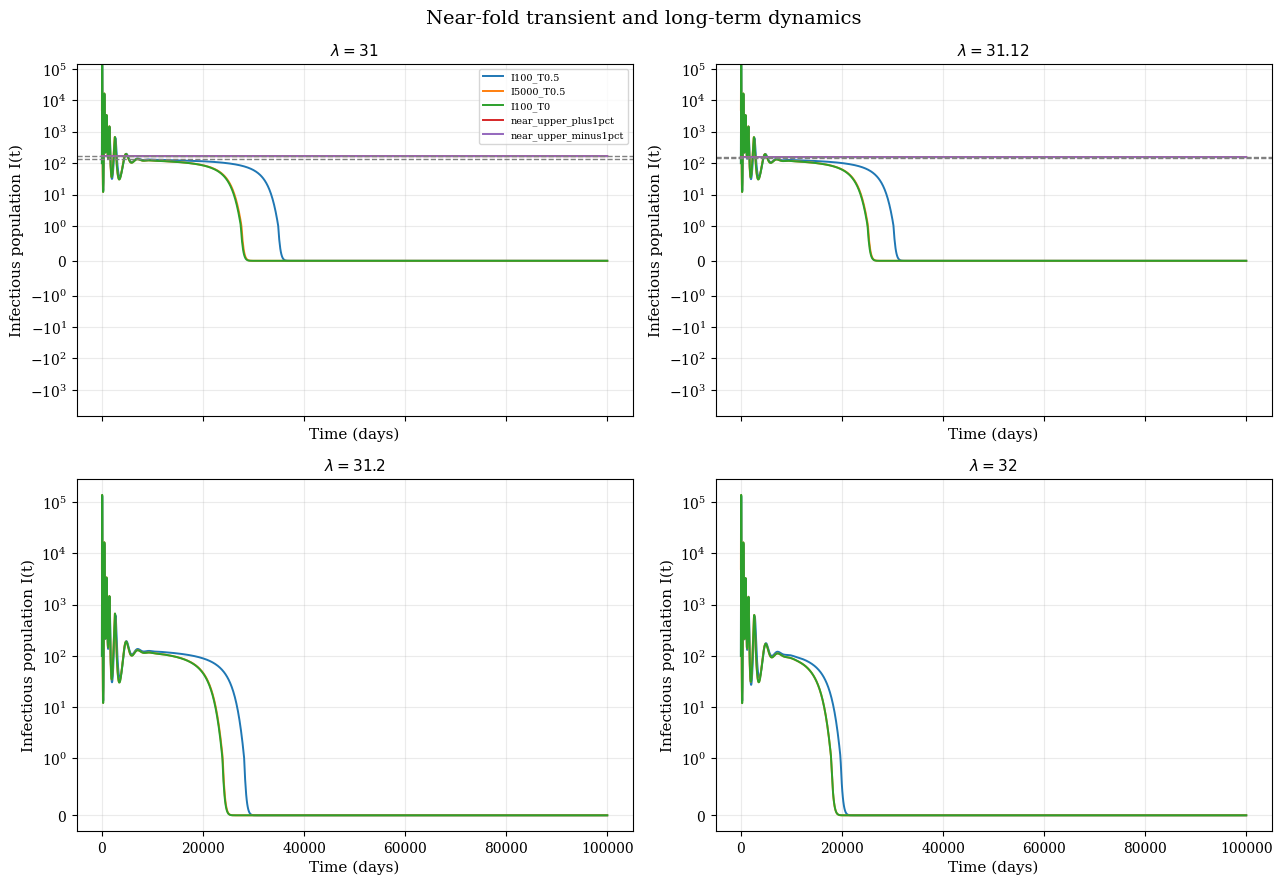

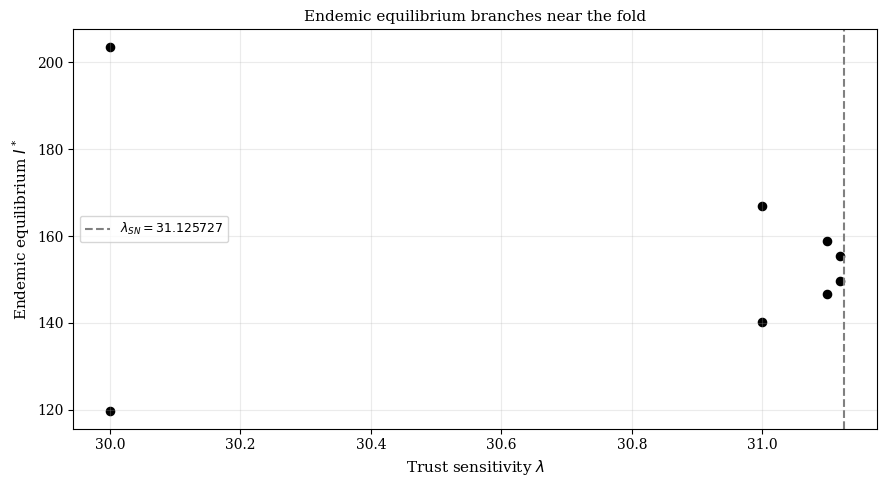

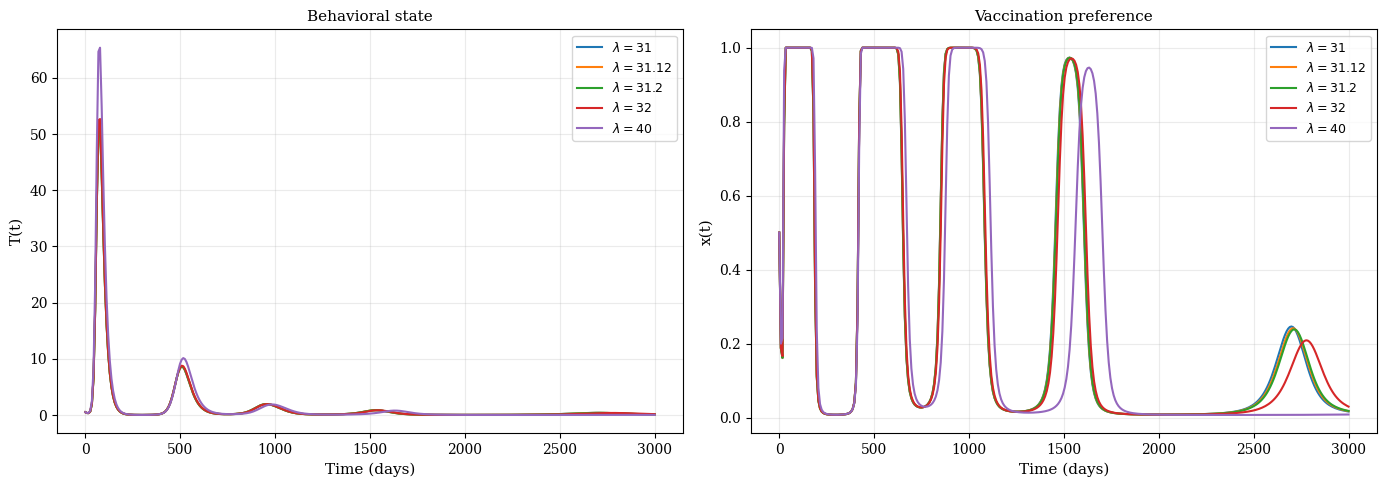


All outputs saved to: /content/reviewer1_comment2_outputs


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from pathlib import Path

# ============================================================
# 1. PARAMETERS
# ============================================================

OUT = Path("reviewer1_comment2_outputs")
OUT.mkdir(exist_ok=True)

N = 1_000_000.0

beta = 0.6
phi = 0.005
eps = 0.8
sigma = 0.25
gamma = 0.2

omegaV = 1 / 365
omegaN = 1 / 730

mu = 0.05
k = 10.0
Tc = 0.5

lambda_SN = 31.125727294988206

lambdas = [30.0, 31.0, 31.1, 31.12, 31.2, 32.0, 40.0]

T_END = 100_000.0


# ============================================================
# 2. VACCINATION PREFERENCE
# ============================================================

def preference(T):
    z = np.clip(k * (T - Tc), -700, 700)
    return 1 / (1 + np.exp(-z))


# ============================================================
# 3. ORIGINAL SEVEN-EQUATION MODEL
# ============================================================

def rhs(t, y, lam):

    S, V, E, I, RN, RV, T = y

    x = preference(T)

    infS = beta * S * I / N
    infV = (1 - eps) * beta * V * I / N

    dS = (
        -infS
        - phi * x * S
        + omegaN * RN
        + omegaV * RV
    )

    dV = phi * x * S - infV

    dE = infS + infV - sigma * E

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omegaN * RN

    dRV = x * gamma * I - omegaV * RV

    dT = lam * I / N - mu * T

    return np.array([
        dS, dV, dE, dI, dRN, dRV, dT
    ])


# ============================================================
# 4. CORRECT ENDEMIC EQUILIBRIUM RECONSTRUCTION
# ============================================================

def endemic_from_I(I, lam):

    T = lam * I / (mu * N)
    x = preference(T)

    r = phi * x / (
        (1 - eps) * beta * I / N
    )

    # Correct susceptible expression:
    # beta*S/N + (1-eps)*beta*V/N = gamma

    S = (gamma * N / beta) / (
        1 + (1 - eps) * r
    )

    V = r * S

    E = gamma * I / sigma

    RN = (1 - x) * gamma * I / omegaN
    RV = x * gamma * I / omegaV

    return np.array([
        S, V, E, I, RN, RV, T
    ])


def mass_residual(I, lam):

    state = endemic_from_I(I, lam)

    return np.sum(state[:6]) - N


# ============================================================
# 5. FIND POSITIVE ENDEMIC EQUILIBRIA
# ============================================================

def equilibria(lam):

    scan = np.unique(
        np.r_[
            np.geomspace(1e-8, 1e6, 6000),
            np.linspace(1, 1000, 12000)
        ]
    )

    values = np.array([
        mass_residual(I, lam)
        for I in scan
    ])

    roots = []

    for j in range(len(scan) - 1):

        if values[j] * values[j + 1] < 0:

            root = brentq(
                mass_residual,
                scan[j],
                scan[j + 1],
                args=(lam,),
                xtol=1e-11
            )

            if not roots or abs(root - roots[-1]) > 1e-5:
                roots.append(root)

    roots = sorted(set(
        round(float(root), 9)
        for root in roots
    ))

    return [
        endemic_from_I(I, lam)
        for I in roots
    ]


# ============================================================
# 6. REDUCED JACOBIAN FOR LOCAL STABILITY
# ============================================================

def reduced_rhs(z, lam):

    V, E, I, RN, RV, T = z

    S = N - V - E - I - RN - RV

    full_state = np.array([
        S, V, E, I, RN, RV, T
    ])

    derivatives = rhs(0, full_state, lam)

    return derivatives[[1, 2, 3, 4, 5, 6]]


def max_real_eigenvalue(y, lam):

    z = y[[1, 2, 3, 4, 5, 6]]

    J = np.zeros((6, 6))

    for j in range(6):

        h = 1e-4 * max(1, abs(z[j]))

        zp = z.copy()
        zm = z.copy()

        zp[j] += h
        zm[j] -= h

        J[:, j] = (
            reduced_rhs(zp, lam)
            - reduced_rhs(zm, lam)
        ) / (2 * h)

    eigenvalues = np.linalg.eigvals(J)

    return np.max(eigenvalues.real)


# ============================================================
# 7. INITIAL CONDITIONS
# ============================================================

def initial_states(lam):

    states = {
        "I100_T0.5": np.array([
            N - 100, 0, 0, 100, 0, 0, 0.5
        ], dtype=float),

        "I5000_T0.5": np.array([
            N - 5000, 0, 0, 5000, 0, 0, 0.5
        ], dtype=float),

        "I100_T0": np.array([
            N - 100, 0, 0, 100, 0, 0, 0
        ], dtype=float),
    }

    eqs = equilibria(lam)

    # Add perturbations near the genuine stable endemic
    # equilibrium only when positive equilibria exist.

    if len(eqs) >= 2:

        upper = eqs[-1]

        delta = 0.01 * upper[3]

        plus = upper.copy()
        plus[0] -= delta
        plus[3] += delta

        minus = upper.copy()
        minus[0] += delta
        minus[3] -= delta

        states["near_upper_plus1pct"] = plus
        states["near_upper_minus1pct"] = minus

    return states


# ============================================================
# 8. SIMULATION SETTINGS
# ============================================================

sample_times = np.array([
    0, 365, 3000, 20000, 50000, 100000
], dtype=float)

plot_times = np.unique(
    np.r_[
        np.linspace(0, 3000, 350),
        np.linspace(3000, T_END, 950),
        sample_times
    ]
)

equilibrium_rows = []
trajectory_rows = []
all_trajectories = {}


# ============================================================
# 9. RUN EQUILIBRIUM AND TRAJECTORY ANALYSES
# ============================================================

for lam in lambdas:

    eqs = equilibria(lam)

    print(
        f"lambda={lam:g}, "
        f"endemic roots="
        f"{[round(y[3], 8) for y in eqs]}"
    )

    # ---------- Equilibrium stability ----------

    for n, y in enumerate(eqs):

        residual = np.max(
            np.abs(rhs(0, y, lam))
        )

        eigenvalue = max_real_eigenvalue(y, lam)

        equilibrium_rows.append({
            "lambda": lam,
            "branch": "lower" if n == 0 else "upper",
            "I_star": y[3],
            "T_star": y[6],
            "x_star": preference(y[6]),
            "max_abs_rhs": residual,
            "max_real_eigenvalue": eigenvalue,
            "local_stability": (
                "stable" if eigenvalue < -1e-9
                else "unstable"
            )
        })

    # ---------- Long-term simulations ----------

    for name, y0 in initial_states(lam).items():

        sol = solve_ivp(
            rhs,
            (0, T_END),
            y0,
            args=(lam,),
            method="BDF",
            rtol=1e-9,
            atol=np.array([1e-5] * 6 + [1e-11]),
            t_eval=plot_times
        )

        if not sol.success:
            raise RuntimeError(
                f"Integration failed: "
                f"lambda={lam}, state={name}: "
                f"{sol.message}"
            )

        # Check nonnegativity
        if np.min(sol.y[:6]) < -1e-3:
            raise RuntimeError(
                f"Materially negative population: "
                f"lambda={lam}, state={name}"
            )

        # Check population conservation
        mass_error = np.max(
            np.abs(
                np.sum(sol.y[:6], axis=0) - N
            )
        )

        if mass_error > 0.1:
            raise RuntimeError(
                f"Mass conservation error: {mass_error}"
            )

        all_trajectories[(lam, name)] = (
            sol.t,
            sol.y[3],
            sol.y[6],
            preference(sol.y[6])
        )

        values = np.interp(
            sample_times,
            sol.t,
            sol.y[3]
        )

        row = {
            "lambda": lam,
            "initial_state": name,
            "initial_I": y0[3],
            "initial_T": y0[6],
            "mass_error_max": mass_error
        }

        for t, value in zip(sample_times, values):
            row[f"I_day_{int(t)}"] = value

        trajectory_rows.append(row)


# ============================================================
# 10. SAVE NUMERICAL TABLES
# ============================================================

df_equilibria = pd.DataFrame(equilibrium_rows)
df_trajectories = pd.DataFrame(trajectory_rows)

df_equilibria.to_csv(
    OUT / "equilibria_stability.csv",
    index=False
)

df_trajectories.to_csv(
    OUT / "trajectory_summary.csv",
    index=False
)

print("\nEQUILIBRIUM RESULTS")
print(
    df_equilibria.to_string(
        index=False,
        float_format=lambda z: f"{z:.9g}"
    )
)

print("\nFINAL INFECTIOUS POPULATIONS")
print(
    df_trajectories[
        ["lambda", "initial_state", "I_day_100000"]
    ].to_string(
        index=False,
        float_format=lambda z: f"{z:.9g}"
    )
)


# ============================================================
# 11. FIGURE A: NEAR-FOLD INFECTION TRAJECTORIES
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

selected_lambdas = [31.0, 31.12, 31.2, 32.0]

for ax, lam in zip(axes.flat, selected_lambdas):

    for name in initial_states(lam):

        t, I, T, x = all_trajectories[(lam, name)]

        ax.plot(
            t,
            np.maximum(I, 0),
            label=name,
            linewidth=1.4
        )

    for y in equilibria(lam):
        ax.axhline(
            y[3],
            color="gray",
            linestyle="--",
            linewidth=1
        )

    ax.set_title(fr"$\lambda={lam:g}$")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylabel("Infectious population I(t)")
    ax.set_xlabel("Time (days)")
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=7)

fig.suptitle(
    "Near-fold transient and long-term dynamics",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    OUT / "near_fold_trajectories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. FIGURE B: ENDEMIC EQUILIBRIA NEAR THE FOLD
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

for lam in lambdas:

    for y in equilibria(lam):
        ax.scatter(
            lam,
            y[3],
            color="black",
            s=35
        )

ax.axvline(
    lambda_SN,
    linestyle="--",
    color="gray",
    label=fr"$\lambda_{{SN}}={lambda_SN:.6f}$"
)

ax.set_xlabel(r"Trust sensitivity $\lambda$")
ax.set_ylabel(r"Endemic equilibrium $I^*$")
ax.set_title("Endemic equilibrium branches near the fold")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "near_fold_equilibria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. FIGURE C: VACCINATION RESPONSE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for lam in [31.0, 31.12, 31.2, 32.0, 40.0]:

    t, I, T, x = all_trajectories[
        (lam, "I100_T0.5")
    ]

    mask = t <= 3000

    axes[0].plot(
        t[mask],
        T[mask],
        label=fr"$\lambda={lam:g}$"
    )

    axes[1].plot(
        t[mask],
        x[mask],
        label=fr"$\lambda={lam:g}$"
    )

axes[0].set_title("Behavioral state")
axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel("T(t)")

axes[1].set_title("Vaccination preference")
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("x(t)")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "near_fold_behavioral_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAll outputs saved to:", OUT.resolve())


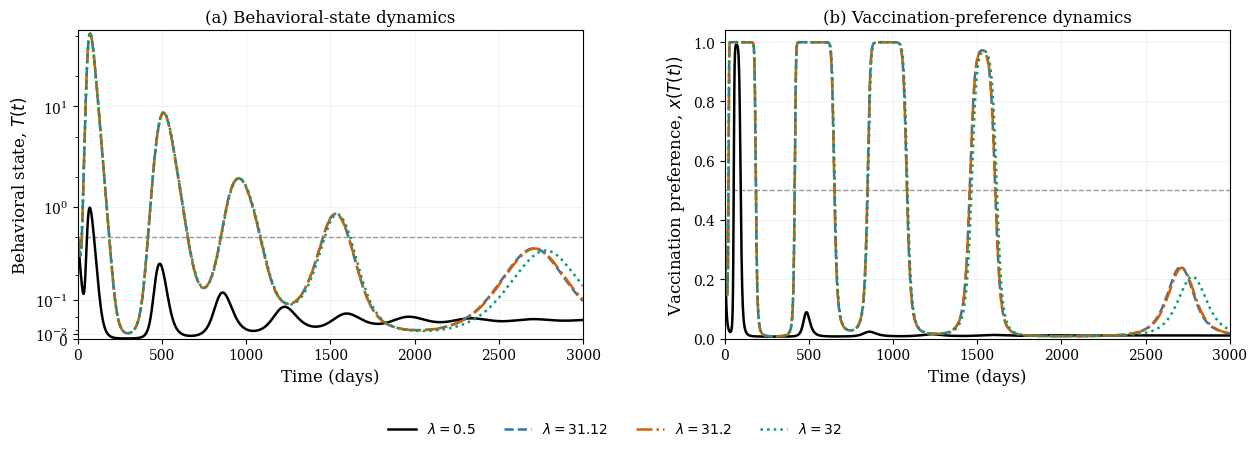


Behavioral response near the saddle-node
Fold location: lambda_SN = 31.12572729
-----------------------------------------------------------------------------------
   lambda        max T        max x      final T      final x     x > 0.5?
    0.500     0.990906     0.992675     0.043718     0.010325          Yes
   31.120    52.756023     1.000000     0.096528     0.017383          Yes
   31.200    52.885381     1.000000     0.100492     0.018073          Yes
   32.000    54.177987     1.000000     0.151329     0.029693          Yes


In [24]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# PARAMETERS
# ============================================================

N = 1_000_000

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1 / 365
omega_N = 1 / 730

mu = 0.05
k = 10
T_c = 0.5

lambda_SN = 31.125727294988206

# Baseline, below-fold, and above-fold comparisons
lambda_values = [0.5, 31.12, 31.2, 32.0]


# ============================================================
# VACCINATION PREFERENCE
# ============================================================

def vaccination_preference(T):
    z = np.clip(k * (T - T_c), -700, 700)
    return 1.0 / (1.0 + np.exp(-z))


# ============================================================
# EPIDEMIC-BEHAVIOR MODEL
# State variables: S, V, E, I, R_N, R_V, T
# ============================================================

def model(t, y, lam):
    S, V, E, I, R_N, R_V, T = y

    x = vaccination_preference(T)

    infection_S = beta * S * I / N
    infection_V = (1 - epsilon) * beta * V * I / N

    dS = (
        -infection_S
        - phi * x * S
        + omega_N * R_N
        + omega_V * R_V
    )

    dV = phi * x * S - infection_V

    dE = infection_S + infection_V - sigma * E

    dI = sigma * E - gamma * I

    dR_N = (1 - x) * gamma * I - omega_N * R_N

    dR_V = x * gamma * I - omega_V * R_V

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dR_N, dR_V, dT]


# ============================================================
# INITIAL CONDITIONS
# Identical for all values of lambda
# ============================================================

S0 = 999_900
V0 = 0
E0 = 0
I0 = 100
RN0 = 0
RV0 = 0
T0 = 0.5

y0 = [S0, V0, E0, I0, RN0, RV0, T0]

t_end = 3000
t_eval = np.linspace(0, t_end, 6001)


# ============================================================
# SOLVE THE MODEL
# ============================================================

results = {}

for lam in lambda_values:

    sol = solve_ivp(
        model,
        (0, t_end),
        y0,
        args=(lam,),
        method="DOP853",
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    if not sol.success:
        raise RuntimeError(
            f"Integration failed for lambda={lam}: {sol.message}"
        )

    T = sol.y[6]
    x = vaccination_preference(T)

    results[lam] = {
        "time": sol.t,
        "T": T,
        "x": x,
        "I": sol.y[3]
    }


# ============================================================
# PUBLICATION FIGURE: TWO PANELS, NO INSETS
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 600
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.8, 4.6),
    sharex=True
)

colors = {
    0.5: "black",
    31.12: "#2878B5",
    31.2: "#D55E00",
    32.0: "#009E73"
}

styles = {
    0.5: "-",
    31.12: "--",
    31.2: "-.",
    32.0: ":"
}

lines = []

for lam in lambda_values:

    r = results[lam]
    label = rf"$\lambda={lam:g}$"

    line, = axes[0].plot(
        r["time"],
        r["T"],
        color=colors[lam],
        linestyle=styles[lam],
        linewidth=1.8,
        label=label
    )

    lines.append(line)

    axes[1].plot(
        r["time"],
        r["x"],
        color=colors[lam],
        linestyle=styles[lam],
        linewidth=1.8,
        label=label
    )


# ============================================================
# PANEL (a): BEHAVIORAL STATE
# ============================================================

axes[0].axhline(
    T_c,
    color="gray",
    linestyle="--",
    linewidth=1.0,
    alpha=0.8,
    zorder=0
)

# Nonlinear scale retaining zero and small positive values.
# Unlike a logarithmic scale, asinh is defined at zero.
axes[0].set_yscale("asinh", linear_width=0.1)

axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel(r"Behavioral state, $T(t)$")
axes[0].set_title("(a) Behavioral-state dynamics")

axes[0].set_ylim(bottom=0)


# ============================================================
# PANEL (b): VACCINATION PREFERENCE
# ============================================================

# This is the sigmoid midpoint:
# x(T_c) = 0.5, NOT an imposed vaccination threshold.
axes[1].axhline(
    vaccination_preference(T_c),
    color="gray",
    linestyle="--",
    linewidth=1.0,
    alpha=0.8,
    zorder=0
)

axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel(r"Vaccination preference, $x(T(t))$")
axes[1].set_title("(b) Vaccination-preference dynamics")

axes[1].set_ylim(0, 1.04)


# ============================================================
# COMMON FORMATTING
# ============================================================

for ax in axes:
    ax.set_xlim(0, t_end)
    ax.set_xticks(np.arange(0, t_end + 1, 500))
    ax.grid(
        alpha=0.18,
        linewidth=0.6
    )
    ax.tick_params(direction="out")

# One shared legend below the panels
fig.legend(
    handles=lines,
    labels=[line.get_label() for line in lines],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=4,
    frameon=False
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.90,
    bottom=0.23,
    wspace=0.28
)

# ============================================================
# SAVE PUBLICATION FILES
# ============================================================

plt.savefig(
    "behavioral_dynamics_near_fold.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "behavioral_dynamics_near_fold.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# NUMERICAL SUMMARY
# ============================================================

print("\nBehavioral response near the saddle-node")
print(f"Fold location: lambda_SN = {lambda_SN:.8f}")
print("-" * 83)

print(
    f"{'lambda':>9} "
    f"{'max T':>12} "
    f"{'max x':>12} "
    f"{'final T':>12} "
    f"{'final x':>12} "
    f"{'x > 0.5?':>12}"
)

for lam in lambda_values:

    T = results[lam]["T"]
    x = results[lam]["x"]

    print(
        f"{lam:9.3f} "
        f"{np.max(T):12.6f} "
        f"{np.max(x):12.6f} "
        f"{T[-1]:12.6f} "
        f"{x[-1]:12.6f} "
        f"{'Yes' if np.any(x > 0.5) else 'No':>12}"
    )


Locally stable branch: Jacobian classification verified.
Unstable branch: Jacobian classification verified.

ANALYTICAL SADDLE-NODE
lambda_SN = 31.1257272950
I_SN      = 152.55004536
x_SN      = 0.01711808
T_SN      = 0.09496462

Reconstructed fold equilibrium
-----------------------------------------------------------------
S        = 172255.733452074317
V        = 805387.999406295596
E        = 122.040036289884
I        = 152.550045362355
R_N      = 21891.047497052088
R_V      = 190.629562925890
T        = 0.094964622216
population_error = 1.1641532182693481e-10

Algebraic-root meeting (NOT the lambda-fold)
-----------------------------------------------------------------
lambda = 7.069658844
I      = 1962.94733222
x      = 0.097569529

Independent numerical checks
-----------------------------------------------------------------
Stable roots verified:   15/15
Unstable roots verified: 15/15


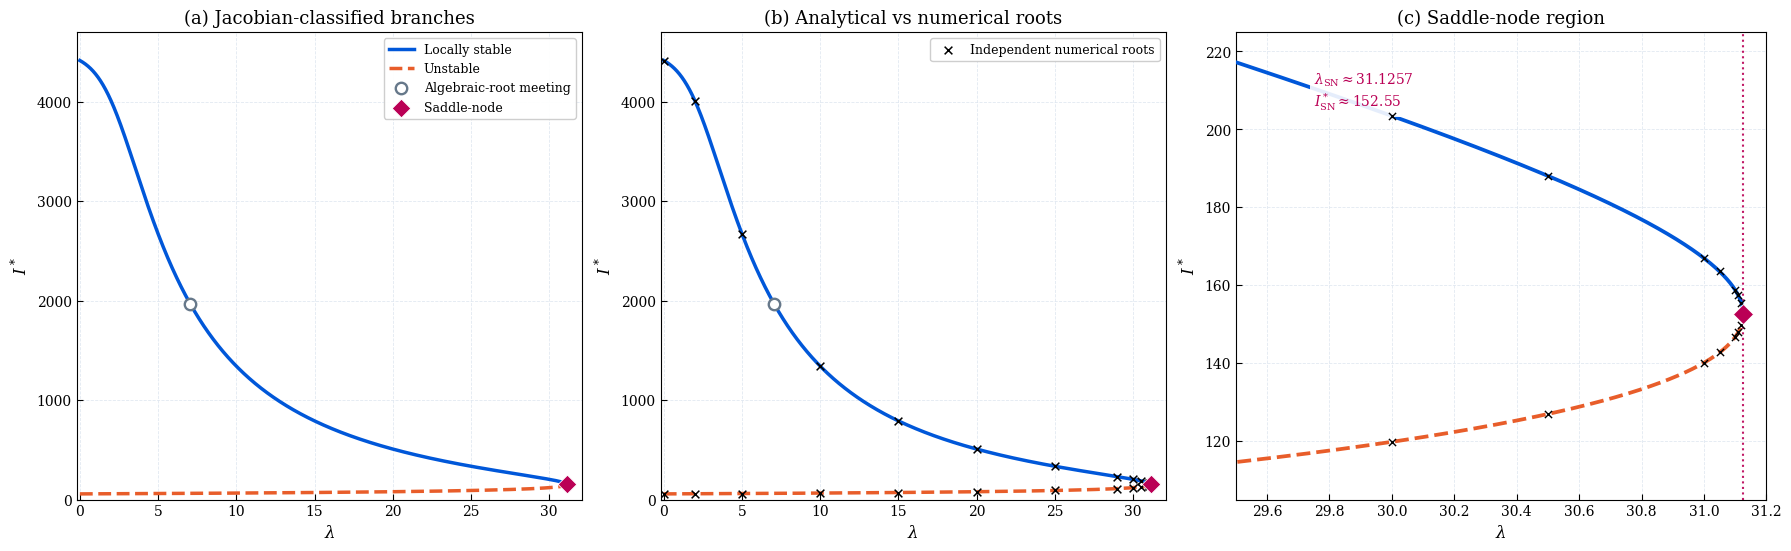


Files saved:
  Figure2_publication_corrected.png
  Figure2_publication_corrected.pdf


In [25]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brentq, minimize_scalar, root
from scipy.special import expit
from matplotlib.lines import Line2D

# ============================================================
# 1. MODEL PARAMETERS
# ============================================================

N = 1_000_000.0

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1.0 / 365.0
omega_N = 1.0 / (365.0 * 2.0)

mu = 0.05
k = 10.0
T_c = 0.5

# ============================================================
# 2. VACCINATION PREFERENCE AND EQUILIBRIUM EQUATIONS
# ============================================================

def vaccination_preference(T):
    return expit(k * (T - T_c))


def trust_from_x(x):
    """Invert x = sigmoid(k*(T-T_c))."""
    return T_c + np.log(x / (1.0 - x)) / k


def quadratic_coefficients(x):
    """
    Population conservation gives

        A I^2 + B I + C = 0

    at fixed vaccination preference x.
    """
    c = phi * x * N / beta

    d = (
        1.0
        + gamma / sigma
        + gamma * (1.0 - x) / omega_N
        + gamma * x / omega_V
    )

    A = d

    B = gamma * N / beta - N + d * c

    C = c * (
        gamma * N / (beta * (1.0 - epsilon)) - N
    )

    return A, B, C


def discriminant(x):
    A, B, C = quadratic_coefficients(x)
    return B * B - 4.0 * A * C


def endemic_roots(x):
    """
    Return both positive endemic infection roots at fixed x.

    Numerically stable quadratic formula.
    """
    A, B, C = quadratic_coefficients(x)
    D = discriminant(x)

    if D < 0:
        return []

    sqrt_D = np.sqrt(max(D, 0.0))

    q = -0.5 * (B + np.copysign(sqrt_D, B))

    if abs(q) < 1e-14:
        candidates = [
            (-B - sqrt_D) / (2.0 * A),
            (-B + sqrt_D) / (2.0 * A),
        ]
    else:
        candidates = [q / A, C / q]

    return sorted(
        float(I)
        for I in candidates
        if np.isfinite(I) and I > 0
    )


def lambda_from_equilibrium(I, x):
    """
    At equilibrium:

        T = lambda*I/(mu*N)

    Hence lambda = mu*N*T/I.
    """
    T = trust_from_x(x)
    return mu * N * T / I


def equilibrium_state(I, x):
    """
    Reconstruct the complete endemic equilibrium:

        (S, V, E, I, R_N, R_V, T)
    """
    c = phi * x * N / beta

    S = (gamma * N / beta) * I / (I + c)

    V = (
        (gamma * N / beta)
        * c
        / ((1.0 - epsilon) * (I + c))
    )

    E = gamma * I / sigma

    R_N = (1.0 - x) * gamma * I / omega_N
    R_V = x * gamma * I / omega_V

    T = trust_from_x(x)

    return np.array([S, V, E, I, R_N, R_V, T])


# ============================================================
# 3. ORIGINAL DIFFERENTIAL EQUATIONS
# ============================================================

def model_rhs(z, lam):
    """
    Full seven-dimensional model.

    Written to support complex-step differentiation.
    """
    S, V, E, I, R_N, R_V, T = z

    x = 1.0 / (1.0 + np.exp(-k * (T - T_c)))

    infection_S = beta * S * I / N
    infection_V = (1.0 - epsilon) * beta * V * I / N

    dS = (
        -infection_S
        - phi * x * S
        + omega_N * R_N
        + omega_V * R_V
    )

    dV = phi * x * S - infection_V

    dE = infection_S + infection_V - sigma * E

    dI = sigma * E - gamma * I

    dR_N = (1.0 - x) * gamma * I - omega_N * R_N

    dR_V = x * gamma * I - omega_V * R_V

    dT = lam * I / N - mu * T

    return np.array([dS, dV, dE, dI, dR_N, dR_V, dT])


# ============================================================
# 4. POPULATION-REDUCED JACOBIAN
# ============================================================

def reduced_rhs(y, lam):
    """
    Eliminate S using conservation:

        S = N - V - E - I - R_N - R_V

    Reduced state:
        y = (V, E, I, R_N, R_V, T)

    This removes the artificial zero eigenvalue associated
    with total-population conservation.
    """
    V, E, I, R_N, R_V, T = y

    S = N - V - E - I - R_N - R_V

    z = np.array([S, V, E, I, R_N, R_V, T])

    return model_rhs(z, lam)[[1, 2, 3, 4, 5, 6]]


def reduced_jacobian(y, lam):
    """
    Accurate Jacobian using complex-step differentiation.
    """
    h = 1e-20

    J = np.zeros((6, 6))

    for j in range(6):
        y_complex = np.asarray(y, dtype=complex).copy()
        y_complex[j] += 1j * h

        J[:, j] = (
            np.imag(reduced_rhs(y_complex, lam)) / h
        )

    return J


def leading_eigenvalue(I, x, lam):
    """Largest real part among reduced-Jacobian eigenvalues."""
    z = equilibrium_state(I, x)
    y = z[[1, 2, 3, 4, 5, 6]]

    eigs = np.linalg.eigvals(reduced_jacobian(y, lam))

    return float(np.max(eigs.real))


# ============================================================
# 5. FIND THE ALGEBRAIC-ROOT MEETING POINT
# ============================================================

# Vaccination preference when lambda = 0, T = 0
x_min = vaccination_preference(0.0)

# Find the x value at which the quadratic discriminant vanishes.
# This is NOT the saddle-node in lambda.

x_meeting = brentq(
    discriminant,
    0.05,
    0.15,
    xtol=1e-14
)

roots_meeting = endemic_roots(x_meeting)

I_meeting = float(np.mean(roots_meeting))

lambda_meeting = lambda_from_equilibrium(
    I_meeting, x_meeting
)

# ============================================================
# 6. FIND THE ACTUAL SADDLE-NODE
# ============================================================

def lower_root_lambda(x):
    roots = endemic_roots(x)

    if not roots:
        return -np.inf

    return lambda_from_equilibrium(roots[0], x)


# The lambda-fold is a maximum of lambda(x) on the
# lower quadratic-root sheet.

fold_result = minimize_scalar(
    lambda x: -lower_root_lambda(x),
    bounds=(0.012, 0.025),
    method="bounded",
    options={"xatol": 1e-15}
)

if not fold_result.success:
    raise RuntimeError("Saddle-node optimization failed.")

x_SN = float(fold_result.x)

I_SN = float(endemic_roots(x_SN)[0])

lambda_SN = float(
    lambda_from_equilibrium(I_SN, x_SN)
)

fold_state = equilibrium_state(I_SN, x_SN)

# ============================================================
# 7. CONSTRUCT BOTH QUADRATIC ROOT SHEETS
# ============================================================

# Dense sampling, particularly near x_SN and x_meeting.
#
# Crucially, we trace BOTH quadratic roots all the way
# to their algebraic meeting point.
#
# Stability is determined separately by the Jacobian.

x_uniform = np.linspace(
    x_min + 1e-11,
    x_meeting - 1e-10,
    3000
)

x_near_fold = np.linspace(
    max(x_min + 1e-10, x_SN - 0.007),
    min(x_meeting - 1e-10, x_SN + 0.007),
    2500
)

x_near_meeting = np.linspace(
    max(x_min + 1e-10, x_meeting - 0.006),
    x_meeting - 1e-10,
    1200
)

x_grid = np.unique(
    np.concatenate([
        x_uniform,
        x_near_fold,
        x_near_meeting,
        [x_SN]
    ])
)


def build_sheets(x_values):
    """
    Each sheet contains:
        (lambda, I, x)

    Sheet 0 = smaller quadratic root
    Sheet 1 = larger quadratic root

    These are ALGEBRAIC sheets, not stability branches.
    """
    sheets = [[], []]

    for x in x_values:
        roots = endemic_roots(x)

        if len(roots) != 2:
            continue

        for sheet_id, I in enumerate(roots):
            lam = lambda_from_equilibrium(I, x)

            if -1e-9 <= lam <= lambda_SN + 1e-7:
                sheets[sheet_id].append([
                    max(0.0, lam),
                    I,
                    x
                ])

    return [np.asarray(s) for s in sheets]


sheets = build_sheets(x_grid)

# ============================================================
# 8. CLASSIFY THE PHYSICAL ENDEMIC BRANCHES
# ============================================================

# The locally stable branch consists of:
#   - the larger quadratic root sheet, and
#   - the portion of the smaller-root sheet AFTER x_SN.
#
# The unstable branch is the smaller-root sheet BEFORE x_SN.
#
# This is checked against the reduced Jacobian below.

lower_sheet, upper_sheet = sheets

unstable_points = lower_sheet[
    lower_sheet[:, 2] < x_SN
]

stable_lower_part = lower_sheet[
    lower_sheet[:, 2] > x_SN
]

stable_upper_part = upper_sheet

# Include the exact meeting point to connect the stable parts.
meeting_point = np.array([
    [lambda_meeting, I_meeting, x_meeting]
])

# Include exact fold in both branches.
fold_point = np.array([
    [lambda_SN, I_SN, x_SN]
])

stable_points = np.vstack([
    stable_lower_part,
    stable_upper_part,
    meeting_point,
    fold_point
])

unstable_points = np.vstack([
    unstable_points,
    fold_point
])

# Sorting by lambda produces a continuous branch:
# one stable and one unstable I* for each lambda < lambda_SN.

stable_points = stable_points[
    np.argsort(stable_points[:, 0])
]

unstable_points = unstable_points[
    np.argsort(unstable_points[:, 0])
]

# ------------------------------------------------------------
# Check the classification against the reduced Jacobian.
# Avoid the exact fold where the leading eigenvalue is zero.
# ------------------------------------------------------------

def verify_branch(points, expected, label):
    sample_indices = np.linspace(
        0, len(points) - 1, 120,
        dtype=int
    )

    violations = []

    for idx in np.unique(sample_indices):
        lam, I, x = points[idx]

        if abs(lam - lambda_SN) < 1e-5:
            continue

        lead = leading_eigenvalue(I, x, lam)

        if expected == "stable" and lead > 1e-8:
            violations.append((lam, I, lead))

        if expected == "unstable" and lead < -1e-8:
            violations.append((lam, I, lead))

    if violations:
        raise RuntimeError(
            f"{label}: Jacobian classification failed: "
            f"{violations[:5]}"
        )

    print(f"{label}: Jacobian classification verified.")


verify_branch(
    stable_points,
    "stable",
    "Locally stable branch"
)

verify_branch(
    unstable_points,
    "unstable",
    "Unstable branch"
)

# ============================================================
# 9. INDEPENDENT NUMERICAL EQUILIBRIUM CHECKS
# ============================================================

# Solve the original equilibrium equations, not just
# the quadratic relation.
#
# Unknowns:
#     S, V, E, I, R_N, R_V, T
#
# Equations:
#     dV=dE=dI=dR_N=dR_V=dT=0
#     S+V+E+I+R_N+R_V=N

def numerical_equilibrium(lam, initial_state):

    def residual(z):
        dz = model_rhs(z, lam)

        # Scale equations to improve root-solver conditioning.
        return np.array([
            dz[1] / 100.0,
            dz[2] / 100.0,
            dz[3] / 100.0,
            dz[4] / 100.0,
            dz[5] / 100.0,
            dz[6],
            (np.sum(z[:6]) - N) / N
        ])

    sol = root(
        residual,
        initial_state,
        method="hybr",
        options={"xtol": 1e-11}
    )

    if (
        np.linalg.norm(residual(sol.x), ord=np.inf) > 1e-7
        or np.min(sol.x[:6]) < -1e-5
    ):
        return None

    return sol.x


def branch_interpolation(points, lam):
    """
    Interpolate I and x on a known equilibrium branch
    to provide a starting guess for an independent solve.
    """
    order = np.argsort(points[:, 0])
    p = points[order]

    I_guess = np.interp(lam, p[:, 0], p[:, 1])
    x_guess = np.interp(lam, p[:, 0], p[:, 2])

    return I_guess, x_guess


# Include multiple points close to the fold.
lambda_checks = np.array([
    0.0,
    2.0,
    5.0,
    10.0,
    15.0,
    20.0,
    25.0,
    29.0,
    30.0,
    30.5,
    31.0,
    31.05,
    31.10,
    31.11,
    31.12
])

numerical_stable = []
numerical_unstable = []

for lam in lambda_checks:

    for points, output in [
        (stable_points, numerical_stable),
        (unstable_points, numerical_unstable)
    ]:

        I_guess, x_guess = branch_interpolation(
            points, lam
        )

        z_guess = equilibrium_state(
            I_guess, x_guess
        )

        z_num = numerical_equilibrium(
            lam, z_guess
        )

        if z_num is None:
            print(
                f"Warning: numerical root not confirmed "
                f"at lambda={lam:.5f}"
            )
            continue

        I_num = z_num[3]
        T_num = z_num[6]
        x_num = vaccination_preference(T_num)

        lead = leading_eigenvalue(
            I_num, x_num, lam
        )

        # Only retain the intended stability branch.
        if output is numerical_stable and lead < 0:
            output.append([lam, I_num])

        elif output is numerical_unstable and lead > 0:
            output.append([lam, I_num])


numerical_stable = np.asarray(
    numerical_stable
).reshape(-1, 2)

numerical_unstable = np.asarray(
    numerical_unstable
).reshape(-1, 2)

# ============================================================
# 10. PRINT THE ANALYTICAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("ANALYTICAL SADDLE-NODE")
print("=" * 65)

print(f"lambda_SN = {lambda_SN:.10f}")
print(f"I_SN      = {I_SN:.8f}")
print(f"x_SN      = {x_SN:.8f}")
print(f"T_SN      = {fold_state[6]:.8f}")

print("\nReconstructed fold equilibrium")
print("-" * 65)

names = ["S", "V", "E", "I", "R_N", "R_V", "T"]

for name, value in zip(names, fold_state):
    print(f"{name:<8} = {value:.12f}")

print(
    "population_error =",
    np.sum(fold_state[:6]) - N
)

print("\nAlgebraic-root meeting (NOT the lambda-fold)")
print("-" * 65)

print(f"lambda = {lambda_meeting:.9f}")
print(f"I      = {I_meeting:.8f}")
print(f"x      = {x_meeting:.9f}")

print("\nIndependent numerical checks")
print("-" * 65)

print(
    f"Stable roots verified:   "
    f"{len(numerical_stable)}/{len(lambda_checks)}"
)

print(
    f"Unstable roots verified: "
    f"{len(numerical_unstable)}/{len(lambda_checks)}"
)

# ============================================================
# 11. PUBLICATION-QUALITY THREE-PANEL FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "savefig.dpi": 350,
})

BLUE = "#0057D9"
ORANGE = "#E85D2A"
MAGENTA = "#BA0055"
GRAY = "#66788A"

fig, axes = plt.subplots(
    1, 3,
    figsize=(17.8, 5.4),
    gridspec_kw={"width_ratios": [1, 1, 1.05]},
    constrained_layout=True
)

ax1, ax2, ax3 = axes

# ------------------------------------------------------------
# PANEL (a): JACOBIAN-CLASSIFIED BRANCHES
# ------------------------------------------------------------

ax1.plot(
    stable_points[:, 0],
    stable_points[:, 1],
    color=BLUE,
    lw=2.5,
    ls="-",
    label="Locally stable",
    zorder=3
)

ax1.plot(
    unstable_points[:, 0],
    unstable_points[:, 1],
    color=ORANGE,
    lw=2.5,
    ls="--",
    label="Unstable",
    zorder=3
)

ax1.scatter(
    [lambda_meeting],
    [I_meeting],
    s=68,
    facecolors="white",
    edgecolors=GRAY,
    linewidths=1.7,
    zorder=7,
    label="Algebraic-root meeting"
)

ax1.scatter(
    [lambda_SN],
    [I_SN],
    s=90,
    marker="D",
    color=MAGENTA,
    edgecolor="white",
    linewidth=0.6,
    zorder=8,
    label="Saddle-node"
)

ax1.set(
    title="(a) Jacobian-classified branches",
    xlabel=r"$\lambda$",
    ylabel=r"$I^*$",
    xlim=(-0.2, 32.1),
    ylim=(0, 4700)
)

ax1.legend(
    loc="upper right",
    framealpha=0.96
)

# ------------------------------------------------------------
# PANEL (b): ANALYTICAL VS INDEPENDENT NUMERICAL ROOTS
# ------------------------------------------------------------

ax2.plot(
    stable_points[:, 0],
    stable_points[:, 1],
    color=BLUE,
    lw=2.5,
    ls="-",
    zorder=2
)

ax2.plot(
    unstable_points[:, 0],
    unstable_points[:, 1],
    color=ORANGE,
    lw=2.5,
    ls="--",
    zorder=2
)

# Numerical checks for both branches
if len(numerical_stable):
    ax2.scatter(
        numerical_stable[:, 0],
        numerical_stable[:, 1],
        color="black",
        marker="x",
        s=31,
        linewidth=1.1,
        zorder=5,
        label="Independent numerical roots"
    )

if len(numerical_unstable):
    ax2.scatter(
        numerical_unstable[:, 0],
        numerical_unstable[:, 1],
        color="black",
        marker="x",
        s=31,
        linewidth=1.1,
        zorder=5
    )

ax2.scatter(
    [lambda_meeting],
    [I_meeting],
    s=68,
    facecolors="white",
    edgecolors=GRAY,
    linewidths=1.7,
    zorder=7
)

ax2.scatter(
    [lambda_SN],
    [I_SN],
    s=90,
    marker="D",
    color=MAGENTA,
    edgecolor="white",
    linewidth=0.6,
    zorder=8
)

ax2.set(
    title="(b) Analytical vs numerical roots",
    xlabel=r"$\lambda$",
    ylabel=r"$I^*$",
    xlim=(-0.2, 32.1),
    ylim=(0, 4700)
)

ax2.legend(
    loc="upper right",
    framealpha=0.96
)

# ------------------------------------------------------------
# PANEL (c): SADDLE-NODE ZOOM
# ------------------------------------------------------------

# Both branches must be visible and approach the SAME point.
# Select data directly from Jacobian-classified curves.

zoom_left = 29.5
zoom_right = 31.2

stable_zoom = stable_points[
    (stable_points[:, 0] >= zoom_left)
    & (stable_points[:, 0] <= lambda_SN + 1e-7)
]

unstable_zoom = unstable_points[
    (unstable_points[:, 0] >= zoom_left)
    & (unstable_points[:, 0] <= lambda_SN + 1e-7)
]

ax3.plot(
    stable_zoom[:, 0],
    stable_zoom[:, 1],
    color=BLUE,
    lw=2.7,
    ls="-",
    label="Locally stable",
    zorder=3
)

ax3.plot(
    unstable_zoom[:, 0],
    unstable_zoom[:, 1],
    color=ORANGE,
    lw=2.7,
    ls="--",
    label="Unstable",
    zorder=3
)

# Plot verified numerical roots near the fold.
# Smaller markers prevent them obscuring the two branches.

for numerical_points in [
    numerical_stable,
    numerical_unstable
]:
    if len(numerical_points) == 0:
        continue

    mask = numerical_points[:, 0] >= 30.0

    ax3.scatter(
        numerical_points[mask, 0],
        numerical_points[mask, 1],
        color="black",
        marker="x",
        s=27,
        linewidth=1.0,
        zorder=5
    )

ax3.axvline(
    lambda_SN,
    color=MAGENTA,
    ls=":",
    lw=1.5,
    alpha=0.9,
    zorder=1
)

ax3.scatter(
    [lambda_SN],
    [I_SN],
    marker="D",
    s=105,
    color=MAGENTA,
    edgecolor="white",
    linewidth=0.6,
    zorder=9
)


ax3.text(
    29.75, 215,
    (
        r"$\lambda_{\mathrm{SN}}\approx31.1257$"
        "\n"
        r"$I_{\mathrm{SN}}^*\approx152.55$"
    ),
    fontsize=10,
    color=MAGENTA,
    ha="left",
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=3
    )
)


ax3.set(
    title="(c) Saddle-node region",
    xlabel=r"$\lambda$",
    ylabel=r"$I^*$",
    xlim=(zoom_left, zoom_right),
    ylim=(105, 225)
)

# ------------------------------------------------------------
# COMMON STYLING
# ------------------------------------------------------------

for ax in axes:
    ax.grid(
        True,
        color="#DDE5EF",
        linestyle="--",
        linewidth=0.6,
        alpha=0.85
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        direction="in",
        length=4
    )

# ============================================================
# 12. SAVE OUTPUTS
# ============================================================

fig.savefig(
    "Figure2_publication_corrected.png",
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "Figure2_publication_corrected.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFiles saved:")
print("  Figure2_publication_corrected.png")
print("  Figure2_publication_corrected.pdf")


STARTING EQUILIBRIA
lambda = 29.00000, I = 230.29068131
lambda = 29.05000, I = 229.00372619

PSEUDO-ARCLENGTH STEP-SIZE CONVERGENCE
         ds  points  lambda_turn        I_turn  lambda_error     I_error  discrete_lambda    discrete_I
0.080000000      17 31.126039976 152.895493393   0.000312681 0.345450393     31.125583035 152.098802571
0.040000000      31 31.125781318 152.634445581   0.000054023 0.084402581     31.125616338 152.154182160
0.020000000      60 31.125738956 152.569409895   0.000011661 0.019366895     31.125625180 152.170247827
0.010000000     117 31.125729810 152.553171308   0.000002515 0.003128308     31.125627499 152.174577009
0.005000000     233 31.125727070 152.551151786   0.000000225 0.001108786     31.125716176 152.675712548

INDEPENDENT NUMERICAL FOLD REFINEMENT
lambda_fold = 31.125727294988
I_fold      = 152.5500430500

Comparison with analytical fold:
Absolute lambda difference = 1.7763568394002505e-14
Absolute I difference = 5.0011180974252056e-08
Fold residual

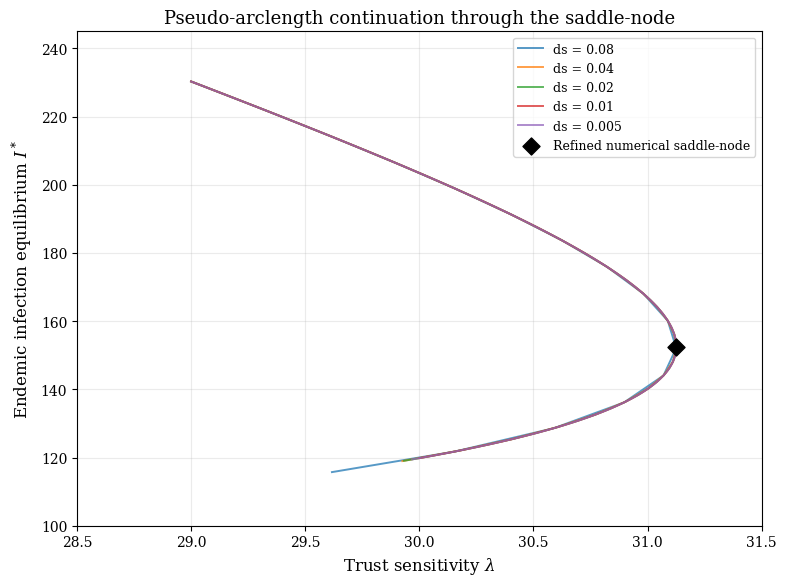

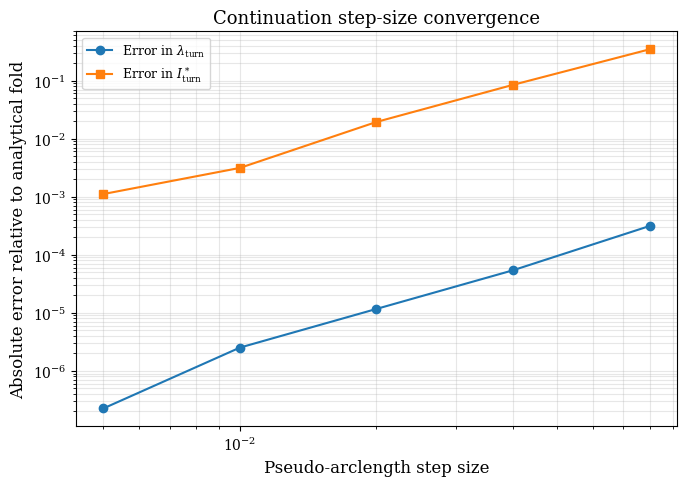


Saved files:
pseudo_arclength_refinement.png
pseudo_arclength_refinement.pdf
continuation_convergence.png
pseudo_arclength_convergence.csv


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import root, brentq
from scipy.special import expit

# ============================================================
# 1. BASELINE MODEL PARAMETERS
# ============================================================

N = 1_000_000.0

beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1.0 / 365.0
omega_N = 1.0 / 730.0

mu = 0.05
k = 10.0
T_c = 0.5

# Reference values from the analytical saddle-node calculation
lambda_SN_reference = 31.125727294988206
I_SN_reference = 152.550043

# ============================================================
# 2. ENDEMIC EQUILIBRIUM EQUATIONS
# ============================================================

def equilibrium_state(I, lam):

    T = lam * I / (mu * N)

    x = expit(k * (T - T_c))

    denominator = beta * I + phi * x * N

    S = gamma * N * I / denominator

    V = (
        phi * x * gamma * N**2
        / ((1.0 - epsilon) * beta * denominator)
    )

    E = gamma * I / sigma

    RN = (1.0 - x) * gamma * I / omega_N

    RV = x * gamma * I / omega_V

    return S, V, E, I, RN, RV, T, x


def equilibrium_residual(I, lam):

    S, V, E, I, RN, RV, T, x = equilibrium_state(I, lam)

    return (S + V + E + I + RN + RV - N) / N


# ============================================================
# 3. SCALED VARIABLES
# ============================================================

# z[0] = I / 100
# z[1] = lambda / 10

I_scale = 100.0
lambda_scale = 10.0


def F(z):

    u, v = z

    I = I_scale * u
    lam = lambda_scale * v

    return equilibrium_residual(I, lam)


# ============================================================
# 4. NUMERICAL JACOBIAN
# ============================================================

# Central finite differences avoid the complex-number
# incompatibility of scipy.special.expit.

def derivative_F(z):

    z = np.asarray(z, dtype=float)

    derivatives = np.zeros(2)

    for j in range(2):

        h = 1e-5 * max(1.0, abs(z[j]))

        z_plus = z.copy()
        z_minus = z.copy()

        z_plus[j] += h
        z_minus[j] -= h

        derivatives[j] = (
            F(z_plus) - F(z_minus)
        ) / (2.0 * h)

    return derivatives


# ============================================================
# 5. STARTING EQUILIBRIA
# ============================================================

# Start on the upper endemic-equilibrium branch.

def upper_root(lam):

    return brentq(
        lambda I: equilibrium_residual(I, lam),
        160.0,
        400.0,
        xtol=1e-12
    )


lambda_0 = 29.0
lambda_1 = 29.05

I_0 = upper_root(lambda_0)
I_1 = upper_root(lambda_1)

z0 = np.array([
    I_0 / I_scale,
    lambda_0 / lambda_scale
])

z1 = np.array([
    I_1 / I_scale,
    lambda_1 / lambda_scale
])

print("=" * 75)
print("STARTING EQUILIBRIA")
print("=" * 75)

print(f"lambda = {lambda_0:.5f}, I = {I_0:.8f}")
print(f"lambda = {lambda_1:.5f}, I = {I_1:.8f}")


# ============================================================
# 6. PSEUDO-ARCLENGTH CONTINUATION
# ============================================================

def continue_branch(ds, max_steps=5000):

    branch = [z0.copy(), z1.copy()]

    for step in range(max_steps):

        previous = branch[-2]
        current = branch[-1]

        # Secant tangent
        tangent = current - previous
        tangent = tangent / np.linalg.norm(tangent)

        # Predictor
        predicted = current + ds * tangent

        # Corrector equations
        def augmented_system(z):

            return np.array([
                F(z),
                np.dot(z - predicted, tangent)
            ])

        def augmented_jacobian(z):

            return np.vstack([
                derivative_F(z),
                tangent
            ])

        solution = root(
            augmented_system,
            predicted,
            jac=augmented_jacobian,
            method="hybr",
            options={
                "xtol": 1e-12,
                "maxfev": 200
            }
        )

        corrected = solution.x

        residual_norm = np.linalg.norm(
            augmented_system(corrected),
            ord=np.inf
        )

        if (
            not np.all(np.isfinite(corrected))
            or residual_norm > 1e-9
        ):
            raise RuntimeError(
                f"Corrector failed: ds={ds}, "
                f"step={step}, residual={residual_norm}"
            )

        branch.append(corrected)

        # Stop once continuation has passed the fold
        # and returned down the lower branch.

        if len(branch) > 10:

            lambda_values = (
                np.asarray(branch)[:, 1] * lambda_scale
            )

            if (
                np.max(lambda_values) > 31.0
                and lambda_values[-1] < 30.0
                and np.argmax(lambda_values) < len(lambda_values) - 5
            ):
                break

    else:
        raise RuntimeError(
            f"Continuation did not pass the fold for ds={ds}"
        )

    branch = np.asarray(branch)

    return np.column_stack([
        branch[:, 1] * lambda_scale,
        branch[:, 0] * I_scale
    ])


# ============================================================
# 7. ESTIMATE TURNING POINT
# ============================================================

def estimate_turning_point(branch):

    lam = branch[:, 0]
    I = branch[:, 1]

    j = np.argmax(lam)

    if j == 0 or j == len(branch) - 1:
        raise RuntimeError("Turning point not bracketed.")

    # Direct estimate from the continuation grid
    discrete_lambda = lam[j]
    discrete_I = I[j]

    # Local quadratic interpolation using the three
    # continuation points around the lambda maximum.

    nearby_I = I[j-1:j+2]
    nearby_lambda = lam[j-1:j+2]

    center = np.mean(nearby_I)

    a, b, c = np.polyfit(
        nearby_I - center,
        nearby_lambda,
        2
    )

    if a >= 0:
        raise RuntimeError(
            "Local quadratic fit does not have a maximum."
        )

    I_vertex = center - b / (2.0 * a)

    lambda_vertex = c - b**2 / (4.0 * a)

    return {
        "discrete_lambda": discrete_lambda,
        "discrete_I": discrete_I,
        "interpolated_lambda": lambda_vertex,
        "interpolated_I": I_vertex
    }


# ============================================================
# 8. STEP-SIZE REFINEMENT STUDY
# ============================================================

step_sizes = [
    0.08,
    0.04,
    0.02,
    0.01,
    0.005
]

results = []
branches = {}

for ds in step_sizes:

    branch = continue_branch(ds)

    branches[ds] = branch

    estimate = estimate_turning_point(branch)

    results.append({
        "ds": ds,
        "points": len(branch),

        "lambda_turn": estimate["interpolated_lambda"],
        "I_turn": estimate["interpolated_I"],

        "lambda_error": abs(
            estimate["interpolated_lambda"]
            - lambda_SN_reference
        ),

        "I_error": abs(
            estimate["interpolated_I"]
            - I_SN_reference
        ),

        "discrete_lambda": estimate["discrete_lambda"],
        "discrete_I": estimate["discrete_I"]
    })

df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("PSEUDO-ARCLENGTH STEP-SIZE CONVERGENCE")
print("=" * 75)

print(
    df.to_string(
        index=False,
        float_format=lambda value: f"{value:.9f}"
    )
)


# ============================================================
# 9. INDEPENDENT NUMERICAL FOLD REFINEMENT
# ============================================================

# The saddle-node satisfies:
#
# F(I, lambda) = 0
# dF/dI = 0
#
# The derivative is evaluated numerically, rather than
# using the analytical equilibrium-root formula.

def fold_system(z):

    return np.array([
        F(z),
        derivative_F(z)[0]
    ])


initial_fold = np.array([
    df.iloc[-1]["I_turn"] / I_scale,
    df.iloc[-1]["lambda_turn"] / lambda_scale
])

fold_solution = root(
    fold_system,
    initial_fold,
    method="hybr",
    options={"xtol": 1e-12}
)

fold_residual = np.linalg.norm(
    fold_system(fold_solution.x),
    ord=np.inf
)

if (
    not np.all(np.isfinite(fold_solution.x))
    or fold_residual > 1e-9
):
    raise RuntimeError(
        "Independent fold refinement failed."
    )

I_fold = fold_solution.x[0] * I_scale
lambda_fold = fold_solution.x[1] * lambda_scale

print("\n" + "=" * 75)
print("INDEPENDENT NUMERICAL FOLD REFINEMENT")
print("=" * 75)

print(f"lambda_fold = {lambda_fold:.12f}")
print(f"I_fold      = {I_fold:.10f}")

print("\nComparison with analytical fold:")

print(
    "Absolute lambda difference =",
    abs(lambda_fold - lambda_SN_reference)
)

print(
    "Absolute I difference =",
    abs(I_fold - I_SN_reference)
)

print("Fold residual =", fold_residual)


# ============================================================
# 10. PLOT PSEUDO-ARCLENGTH CONTINUATION
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for ds in step_sizes:

    branch = branches[ds]

    ax.plot(
        branch[:, 0],
        branch[:, 1],
        linewidth=1.4,
        alpha=0.75,
        label=f"ds = {ds}"
    )

ax.scatter(
    [lambda_fold],
    [I_fold],
    color="black",
    marker="D",
    s=75,
    zorder=10,
    label="Refined numerical saddle-node"
)

ax.set_xlabel(r"Trust sensitivity $\lambda$")
ax.set_ylabel(r"Endemic infection equilibrium $I^*$")

ax.set_title(
    "Pseudo-arclength continuation through the saddle-node"
)

ax.set_xlim(28.5, 31.5)
ax.set_ylim(100, 245)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    "pseudo_arclength_refinement.png",
    dpi=350,
    bbox_inches="tight"
)

plt.savefig(
    "pseudo_arclength_refinement.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. PLOT STEP-SIZE CONVERGENCE
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(
    df["ds"],
    df["lambda_error"],
    "o-",
    label=r"Error in $\lambda_{\mathrm{turn}}$"
)

ax.loglog(
    df["ds"],
    df["I_error"],
    "s-",
    label=r"Error in $I_{\mathrm{turn}}^*$"
)

ax.set_xlabel("Pseudo-arclength step size")
ax.set_ylabel("Absolute error relative to analytical fold")

ax.set_title("Continuation step-size convergence")

ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "continuation_convergence.png",
    dpi=350,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. EXPORT RESULTS
# ============================================================

df.to_csv(
    "pseudo_arclength_convergence.csv",
    index=False
)

print("\nSaved files:")
print("pseudo_arclength_refinement.png")
print("pseudo_arclength_refinement.pdf")
print("continuation_convergence.png")
print("pseudo_arclength_convergence.csv")
